# EDA - Vegetation change 1953 vs 2023 (Braulio valley)

**Kernel:** R (IRkernel). One-time setup in an R console: `install.packages('IRkernel'); IRkernel::installspec()`, then in VS Code install the *Jupyter* extension and select the **R** kernel (top right). Run cells with Shift+Enter.

# 0. Setup

Put the two `.xlsx` files in the same folder as this notebook (or change `data_dir`).
Run cell by cell with Shift+Enter.

In [1]:
needed <- c(
  "tidyverse", "readxl", "vegan",
  "patchwork", "ggrepel", "knitr"
)

# Install only missing packages
to_install <- needed[!needed %in% rownames(installed.packages())]

if (length(to_install)) {
  install.packages(
    to_install,
    repos = "https://cloud.r-project.org",
    type = "binary"
  )
}

# Load packages
invisible(lapply(needed, library, character.only = TRUE))

set.seed(42)
theme_set(theme_minimal(base_size = 11))

period_cols <- c("1953" = "#D95F02", "2023" = "#1B9E77")

data_dir <- "data/"
dir.create("outputs", showWarnings = FALSE)

options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

kable <- function(x, caption = NULL, digits = NULL, ...) {
  args <- list(x = x, format = "html", caption = caption, ...)
  if (!is.null(digits)) args$digits <- digits

  html <- as.character(do.call(knitr::kable, args))
  IRdisplay::display_html(html)
  invisible(x)
}

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Le chargement a nécessité le package : permute

Le chargement a nécessité le package : lattice



## 0.1 Load and rename

The environmental file has long column names with units; I rename them by position
(and check there are 50) so the rest of the code stays readable.

In [2]:
env_raw <- read_excel(file.path(data_dir, "Environmental_variables.xlsx"), na = c("", "NA"))
sp_raw  <- read_excel(file.path(data_dir, "Species_data_final.xlsx"), na = c("", "NA"))

short_names <- c(
  "plot_id", "year", "elevation", "slope", "eastness", "northness", "log_spi",
  "morphology", "livestock_units", "solar_rad", "mat", "map", "summer_temp",
  "summer_prec", "shm", "liv_temp", "liv_light", "gdd5", "snow_days",
  "mineralogy", "liv_ph", "liv_nutrients", "liv_humus", "liv_moisture",
  "shannon", "evenness", "rc_trees", "rc_shrubs", "rc_dwarf_shrubs", "rc_herbs",
  "rc_graminoids", "rc_legumes", "rc_lichens", "rc_mosses",
  "p_competitive", "p_crs", "p_ruderal", "p_stress_tol",
  "pc1_thermal", "pc2_soil", "richness", "cover_total", "cover_vascular",
  "cover_lichens", "cover_mosses", "lat", "lon",
  "assoc_abbr", "association", "habitat"
)
stopifnot(ncol(env_raw) == length(short_names))

env <- env_raw %>%
  set_names(short_names) %>%
  mutate(
    plot_id = as.character(plot_id),
    base_id = str_remove(plot_id, "_23$"),          # same permanent plot in both years
    period  = factor(year, levels = c(1953, 2023)),
    across(c(morphology, mineralogy, assoc_abbr, association, habitat), as.factor)
  )

sp <- sp_raw %>% rename(plot_id = plot_ID) %>% mutate(plot_id = as.character(plot_id))
comm <- sp %>% column_to_rownames("plot_id") %>% as.matrix()   # plots x taxa (numeric)
stopifnot(is.numeric(comm), !anyNA(comm))

# variable groups used throughout
topo      <- c("elevation", "slope", "eastness", "northness", "log_spi", "solar_rad", "livestock_units")
climate   <- c("mat", "map", "summer_temp", "summer_prec", "shm", "gdd5", "snow_days")
liv       <- c("liv_temp", "liv_light", "liv_ph", "liv_nutrients", "liv_humus", "liv_moisture",
               "pc1_thermal", "pc2_soil")
diversity <- c("richness", "shannon", "evenness", "cover_total", "cover_vascular",
               "cover_lichens", "cover_mosses")
growth    <- c("rc_trees", "rc_shrubs", "rc_dwarf_shrubs", "rc_herbs", "rc_graminoids",
               "rc_legumes", "rc_lichens", "rc_mosses")
strategy  <- c("p_competitive", "p_crs", "p_ruderal", "p_stress_tol")
num_vars  <- c(topo, climate, liv, diversity, growth, strategy)

tibble(table = c("Environmental", "Species"),
       rows = c(nrow(env), nrow(comm)),
       columns = c(ncol(env), ncol(comm))) %>% kable()

table,rows,columns
Environmental,84,52
Species,83,373


# 1. Structure and integrity

## 1.1 Plot IDs and pairing between years

In 2023 plots are named `<id>_23`. `base_id` links the two surveys of the same plot.

In [3]:
cat("Env: unique plot_id =", n_distinct(env$plot_id), "of", nrow(env), "rows\n")
cat("Species: unique plot_id =", n_distinct(rownames(comm)), "of", nrow(comm), "rows\n\n")

cat("In env but not in species table:", paste(setdiff(env$plot_id, rownames(comm)), collapse = ", "), "\n")
cat("In species but not in env table:", paste(setdiff(rownames(comm), env$plot_id), collapse = ", "), "\n\n")

env %>% count(period) %>% kable(caption = "Plots per survey year (environmental table)")

paired_ids <- intersect(env$base_id[env$period == "1953"], env$base_id[env$period == "2023"])
cat("Plots with both years in env table:", length(paired_ids), "\n")

# plots with species data in BOTH years
pair_ids_sp <- paired_ids[paired_ids %in% rownames(comm) &
                          paste0(paired_ids, "_23") %in% rownames(comm)]
cat("Plots with both years in species table:", length(pair_ids_sp), "\n")
cat("Plots dropped from paired species analyses:", paste(setdiff(paired_ids, pair_ids_sp), collapse = ", "), "\n")

env_sp <- env %>% filter(plot_id %in% rownames(comm)) %>%
  arrange(match(plot_id, rownames(comm)))
stopifnot(identical(env_sp$plot_id, rownames(comm)))

Env: unique plot_id = 84 of 84 rows
Species: unique plot_id = 83 of 83 rows

In env but not in species table: 17bis 
In species but not in env table:  



period,n
1953,42
2023,42


Plots with both years in env table: 42 
Plots with both years in species table: 41 
Plots dropped from paired species analyses: 17bis 


## 1.2 Relocation check: are 1953 and 2023 plots in the same place?

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       0       0       0       0       0 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       0       0       0       0       0 

base_id,dist_m,elev_diff
10,0,0
11,0,0
12,0,0
16,0,0
17,0,0
33,0,0
35,0,0
36,0,0


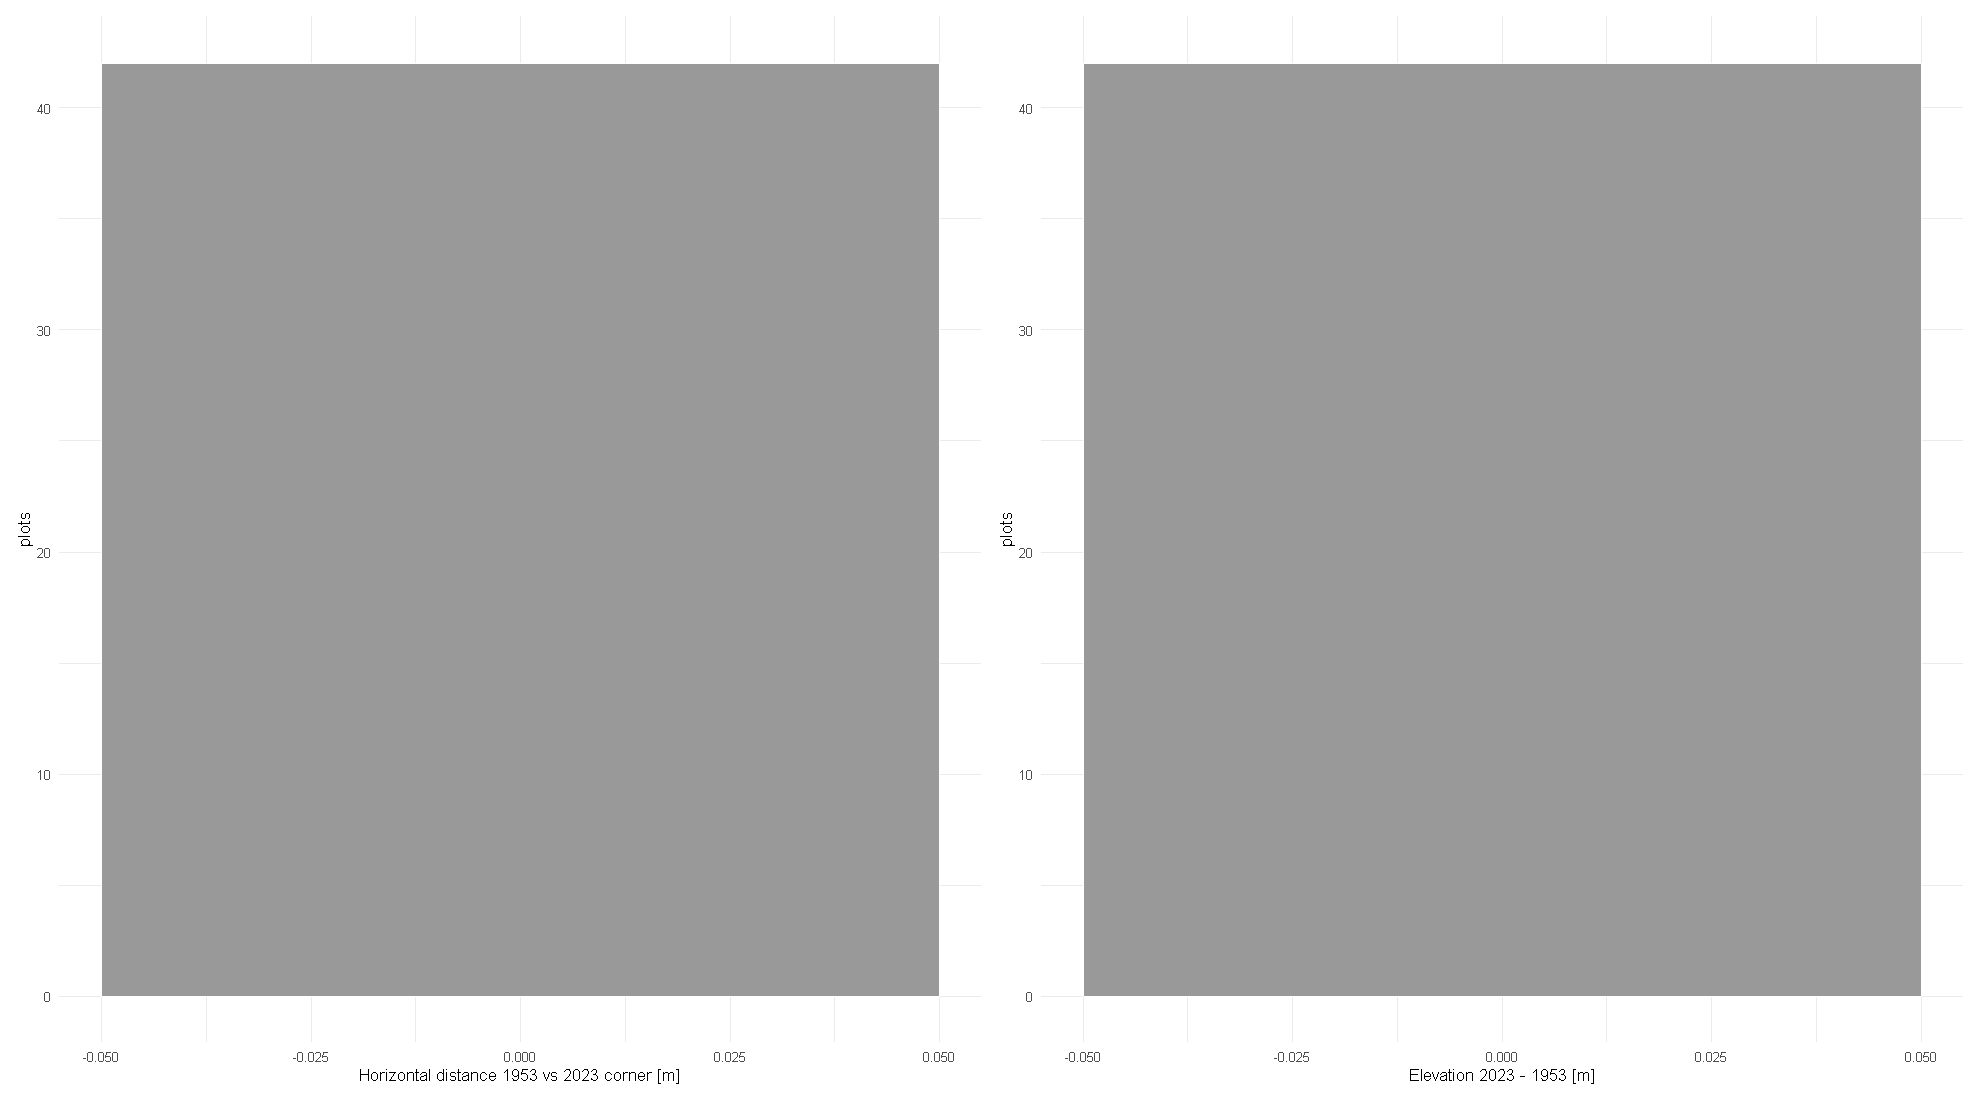

In [4]:
haversine <- function(lat1, lon1, lat2, lon2) {
  r <- 6371000; p <- pi / 180
  a <- sin((lat2 - lat1) * p / 2)^2 +
       cos(lat1 * p) * cos(lat2 * p) * sin((lon2 - lon1) * p / 2)^2
  2 * r * asin(sqrt(a))
}

reloc <- env %>%
  filter(base_id %in% paired_ids) %>%
  select(base_id, period, lat, lon, elevation) %>%
  pivot_wider(names_from = period, values_from = c(lat, lon, elevation)) %>%
  mutate(dist_m = haversine(lat_1953, lon_1953, lat_2023, lon_2023),
         elev_diff = elevation_2023 - elevation_1953)

summary(reloc$dist_m)
summary(reloc$elev_diff)

p1 <- ggplot(reloc, aes(dist_m)) + geom_histogram(bins = 20, fill = "grey60", colour = "white") +
  labs(x = "Horizontal distance 1953 vs 2023 corner [m]", y = "plots")
p2 <- ggplot(reloc, aes(elev_diff)) + geom_histogram(bins = 20, fill = "grey60", colour = "white") +
  labs(x = "Elevation 2023 - 1953 [m]", y = "plots")
p1 + p2

reloc %>% arrange(desc(dist_m)) %>% select(base_id, dist_m, elev_diff) %>% head(8) %>% kable(digits = 1,
  caption = "Plots with largest displacement (check these first)")

## 1.3 Internal consistency of the environmental table

name,value
sum_growth_min,1.000
sum_growth_max,1.000
sum_strategy_min,0.991
sum_strategy_max,1.000


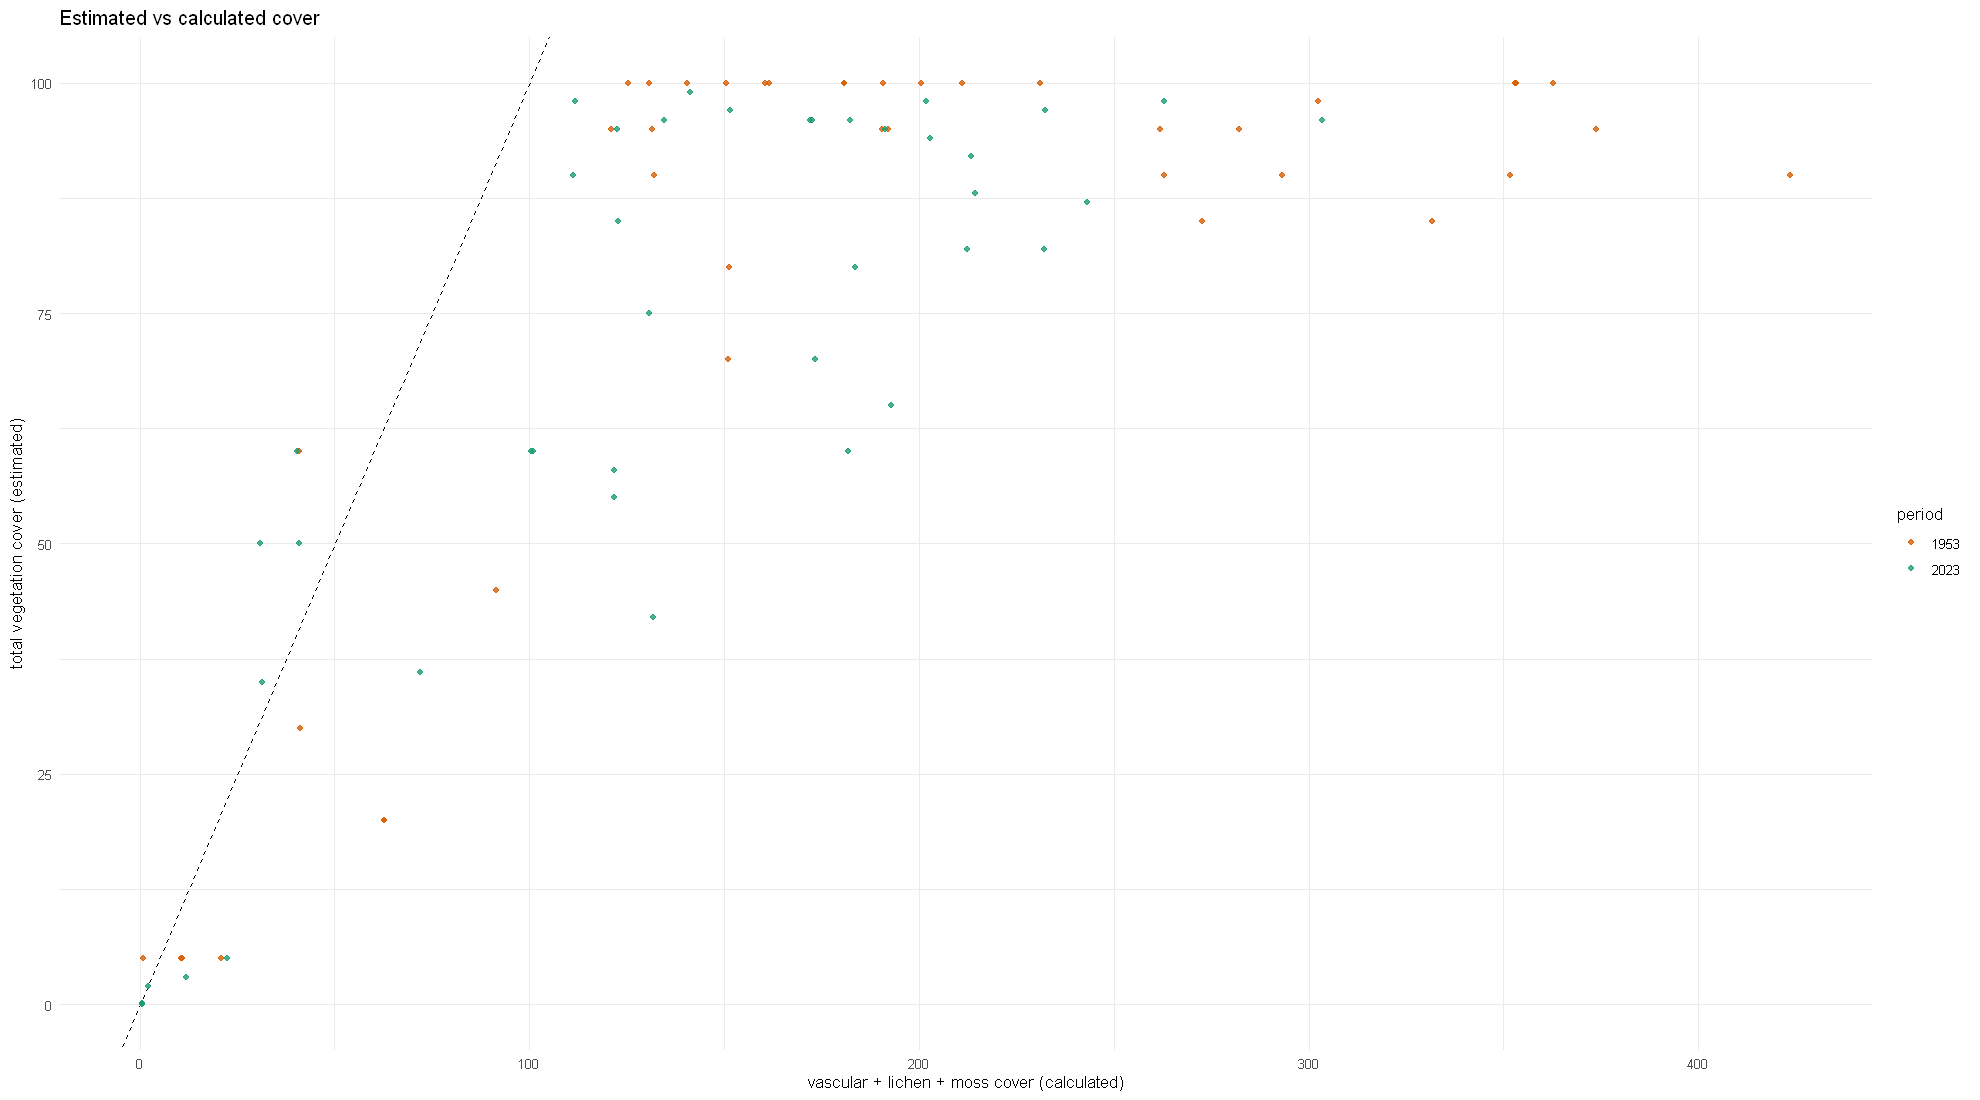

In [5]:
env %>%
  mutate(sum_growth   = rowSums(across(all_of(growth))),
         sum_strategy = rowSums(across(all_of(strategy)))) %>%
  summarise(across(c(sum_growth, sum_strategy), list(min = ~ min(.x, na.rm = TRUE), max = ~ max(.x, na.rm = TRUE)))) %>%
  pivot_longer(everything()) %>% kable(digits = 3,
  caption = "Relative cover of growth forms and CSR proportions should sum to ~1 (note: they are proportions, not %)")

env %>%
  mutate(cover_sum_calc = cover_vascular + cover_lichens + cover_mosses) %>%
  ggplot(aes(cover_sum_calc, cover_total, colour = period)) +
  geom_abline(slope = 1, linetype = 2) + geom_point(alpha = .8, na.rm = TRUE) +
  scale_colour_manual(values = period_cols) +
  labs(x = "vascular + lichen + moss cover (calculated)", y = "total vegetation cover (estimated)",
       title = "Estimated vs calculated cover")

# 2. Missing data and zeros

In [6]:
na_env <- env %>%
  summarise(across(everything(), ~ sum(is.na(.x)))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "n_na") %>%
  mutate(pct_na = round(100 * n_na / nrow(env), 2)) %>%
  arrange(desc(n_na))

na_env %>% filter(n_na > 0) %>% kable(caption = "Environmental table: variables with missing values")
cat("Total NA cells in species table:", sum(is.na(comm)), "\n")

# which rows are affected
env %>% filter(if_any(everything(), is.na)) %>%
  select(plot_id, year, where(~ anyNA(.x))) %>% kable(caption = "Rows with missing values")

variable,n_na,pct_na
cover_total,1,1.19


Total NA cells in species table: 0 


plot_id,year,cover_total
138,1953,NA


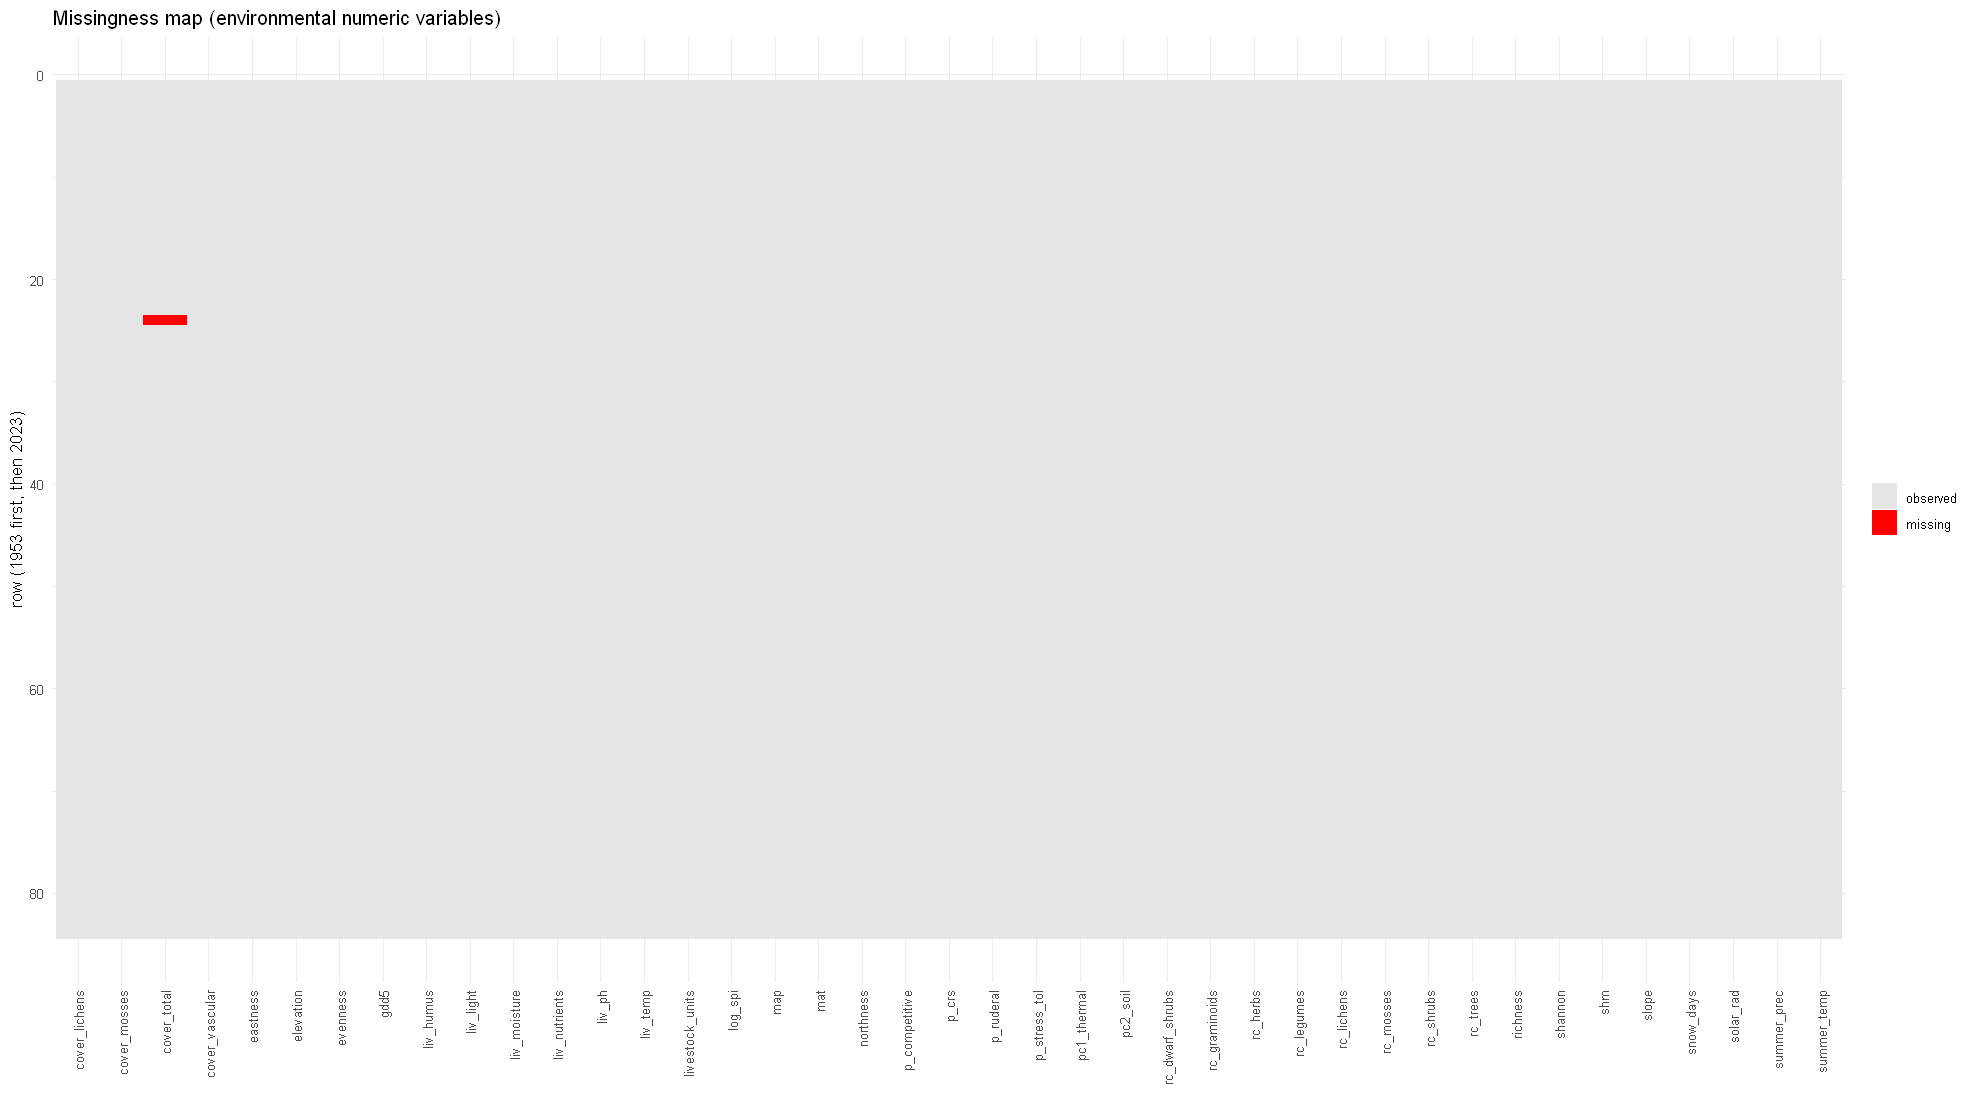

In [7]:
env %>%
  mutate(row = row_number()) %>%
  select(row, all_of(num_vars)) %>%
  pivot_longer(
    -row,
    names_to = "name",
    values_to = "value",
    values_transform = list(value = as.character)
  ) %>%
  ggplot(aes(name, row, fill = is.na(value))) +
  geom_tile() +
  scale_fill_manual(
    values = c("grey90", "red"),
    labels = c("observed", "missing"),
    name = NULL
  ) +
  scale_y_reverse() +
  labs(
    x = NULL,
    y = "row (1953 first, then 2023)",
    title = "Missingness map (environmental numeric variables)"
  ) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5))

In [8]:
env %>%
  summarise(across(all_of(num_vars), ~ mean(.x == 0, na.rm = TRUE) * 100)) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "pct_zero") %>%
  filter(pct_zero > 0) %>% arrange(desc(pct_zero)) %>%
  kable(digits = 1, caption = "% of plots where the variable is exactly 0")

env %>%
  group_by(period) %>%
  summarise(across(all_of(num_vars), n_distinct)) %>%
  pivot_longer(-period, names_to = "variable", values_to = "n_unique") %>%
  filter(n_unique <= 2) %>%
  kable(caption = "Variables with <= 2 distinct values within a period (near-constant: check before modelling)")

variable,pct_zero
rc_trees,94.0
rc_shrubs,85.7
p_ruderal,59.5
rc_legumes,58.3
cover_lichens,51.2
rc_lichens,51.2
cover_mosses,38.1
rc_dwarf_shrubs,38.1
rc_mosses,36.9
livestock_units,28.6


period,variable,n_unique
1953,livestock_units,1
1953,rc_trees,2
2023,livestock_units,2


# 3. Environmental variables

## 3.1 Summary table by period

In [9]:
env %>%
  select(all_of(num_vars)) %>%
  summarise(across(everything(), ~ class(.x))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "class") %>%
  filter(class != "numeric")

variable,class
<chr>,<chr>


In [10]:
env <- env %>%
  mutate(cover_total = as.numeric(cover_total))

In [11]:
env_summary <- env %>%
  select(period, all_of(num_vars)) %>%
  pivot_longer(-period, names_to = "variable") %>%
  group_by(variable, period) %>%
  summarise(n = sum(!is.na(value)), mean = mean(value, na.rm = TRUE), sd = sd(value, na.rm = TRUE),
            median = median(value, na.rm = TRUE), min = min(value, na.rm = TRUE),
            max = max(value, na.rm = TRUE), .groups = "drop") %>%
  mutate(variable = factor(variable, levels = num_vars)) %>% arrange(variable, period)

env_summary %>% mutate(across(where(is.numeric), ~ round(.x, 3)))
write_csv(env_summary, "outputs/env_summary_by_period.csv")

variable,period,n,mean,sd,median,min,max
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
elevation,1953,42,2534.288,193.074,2608.850,2005.200,2744.200
elevation,2023,42,2534.288,193.074,2608.850,2005.200,2744.200
slope,1953,42,19.345,12.526,20.205,0.000,59.830
slope,2023,42,19.345,12.526,20.205,0.000,59.830
eastness,1953,42,-0.149,0.665,-0.340,-0.980,1.000
eastness,2023,42,-0.149,0.665,-0.340,-0.980,1.000
northness,1953,42,-0.099,0.743,-0.260,-1.000,1.000
northness,2023,42,-0.099,0.743,-0.260,-1.000,1.000
log_spi,1953,42,4.003,1.663,4.230,0.010,7.750


## 3.2 Distributions by period

In [12]:
plot_dist <- function(vars, ncol = 4) {
  env %>% select(period, all_of(vars)) %>% pivot_longer(-period) %>%
    ggplot(aes(value, fill = period, colour = period)) +
    geom_density(alpha = .35, na.rm = TRUE) +
    facet_wrap(~ name, scales = "free", ncol = ncol) +
    scale_fill_manual(values = period_cols) + scale_colour_manual(values = period_cols) +
    labs(x = NULL, y = "density")
}
plot_box <- function(vars, ncol = 4) {
  env %>% select(period, all_of(vars)) %>% pivot_longer(-period) %>%
    ggplot(aes(period, value, fill = period)) +
    geom_boxplot(outlier.shape = NA, alpha = .5, na.rm = TRUE) +
    geom_jitter(width = .12, size = 1, alpha = .6, na.rm = TRUE) +
    facet_wrap(~ name, scales = "free_y", ncol = ncol) +
    scale_fill_manual(values = period_cols) + guides(fill = "none") + labs(x = NULL, y = NULL)
}

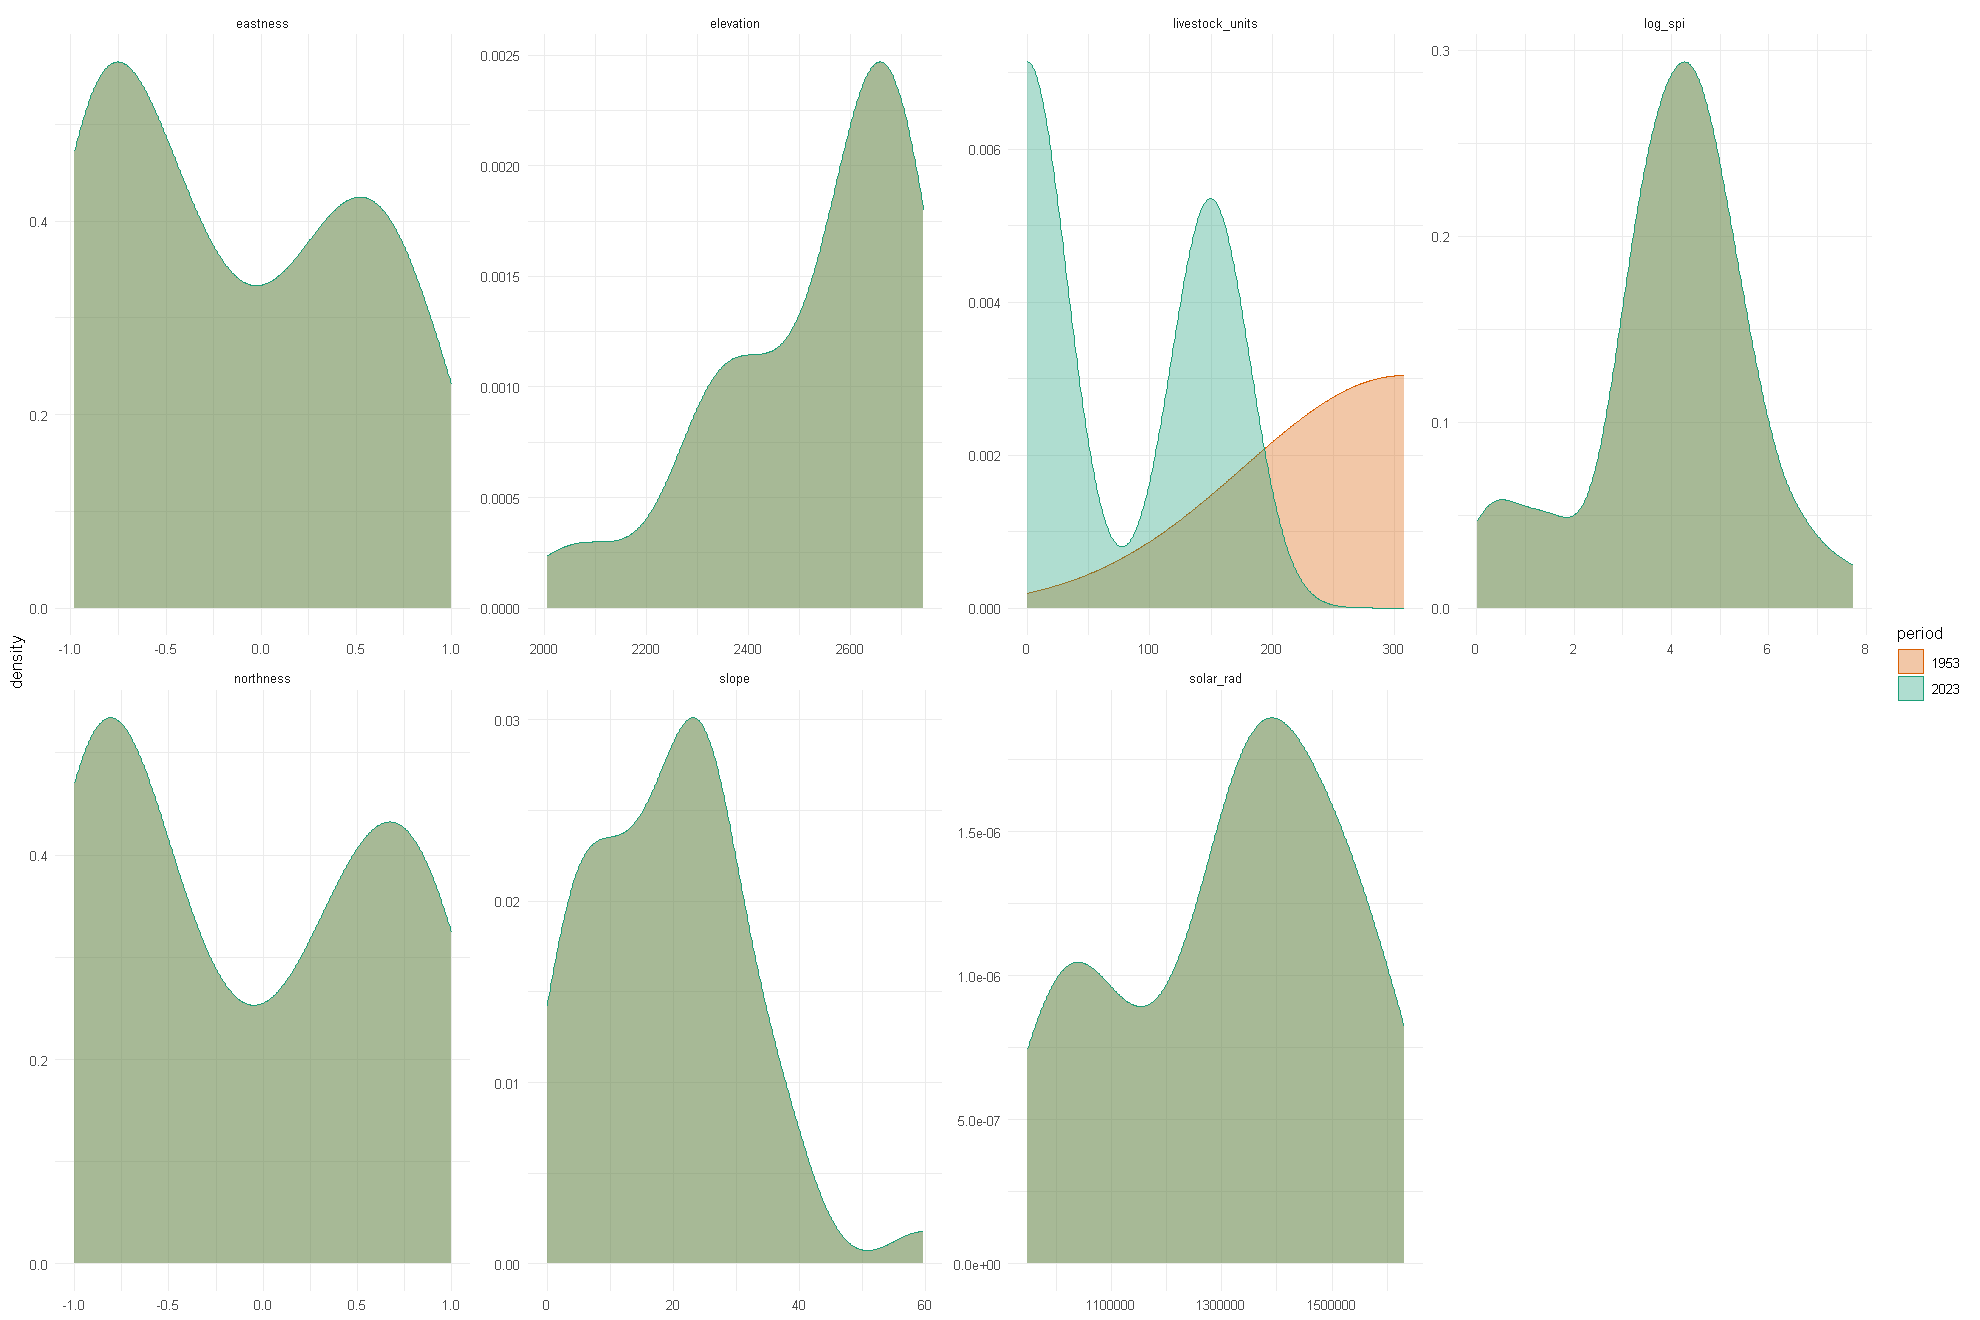

In [13]:
options(repr.plot.width = 18, repr.plot.height = 12)
plot_dist(topo)

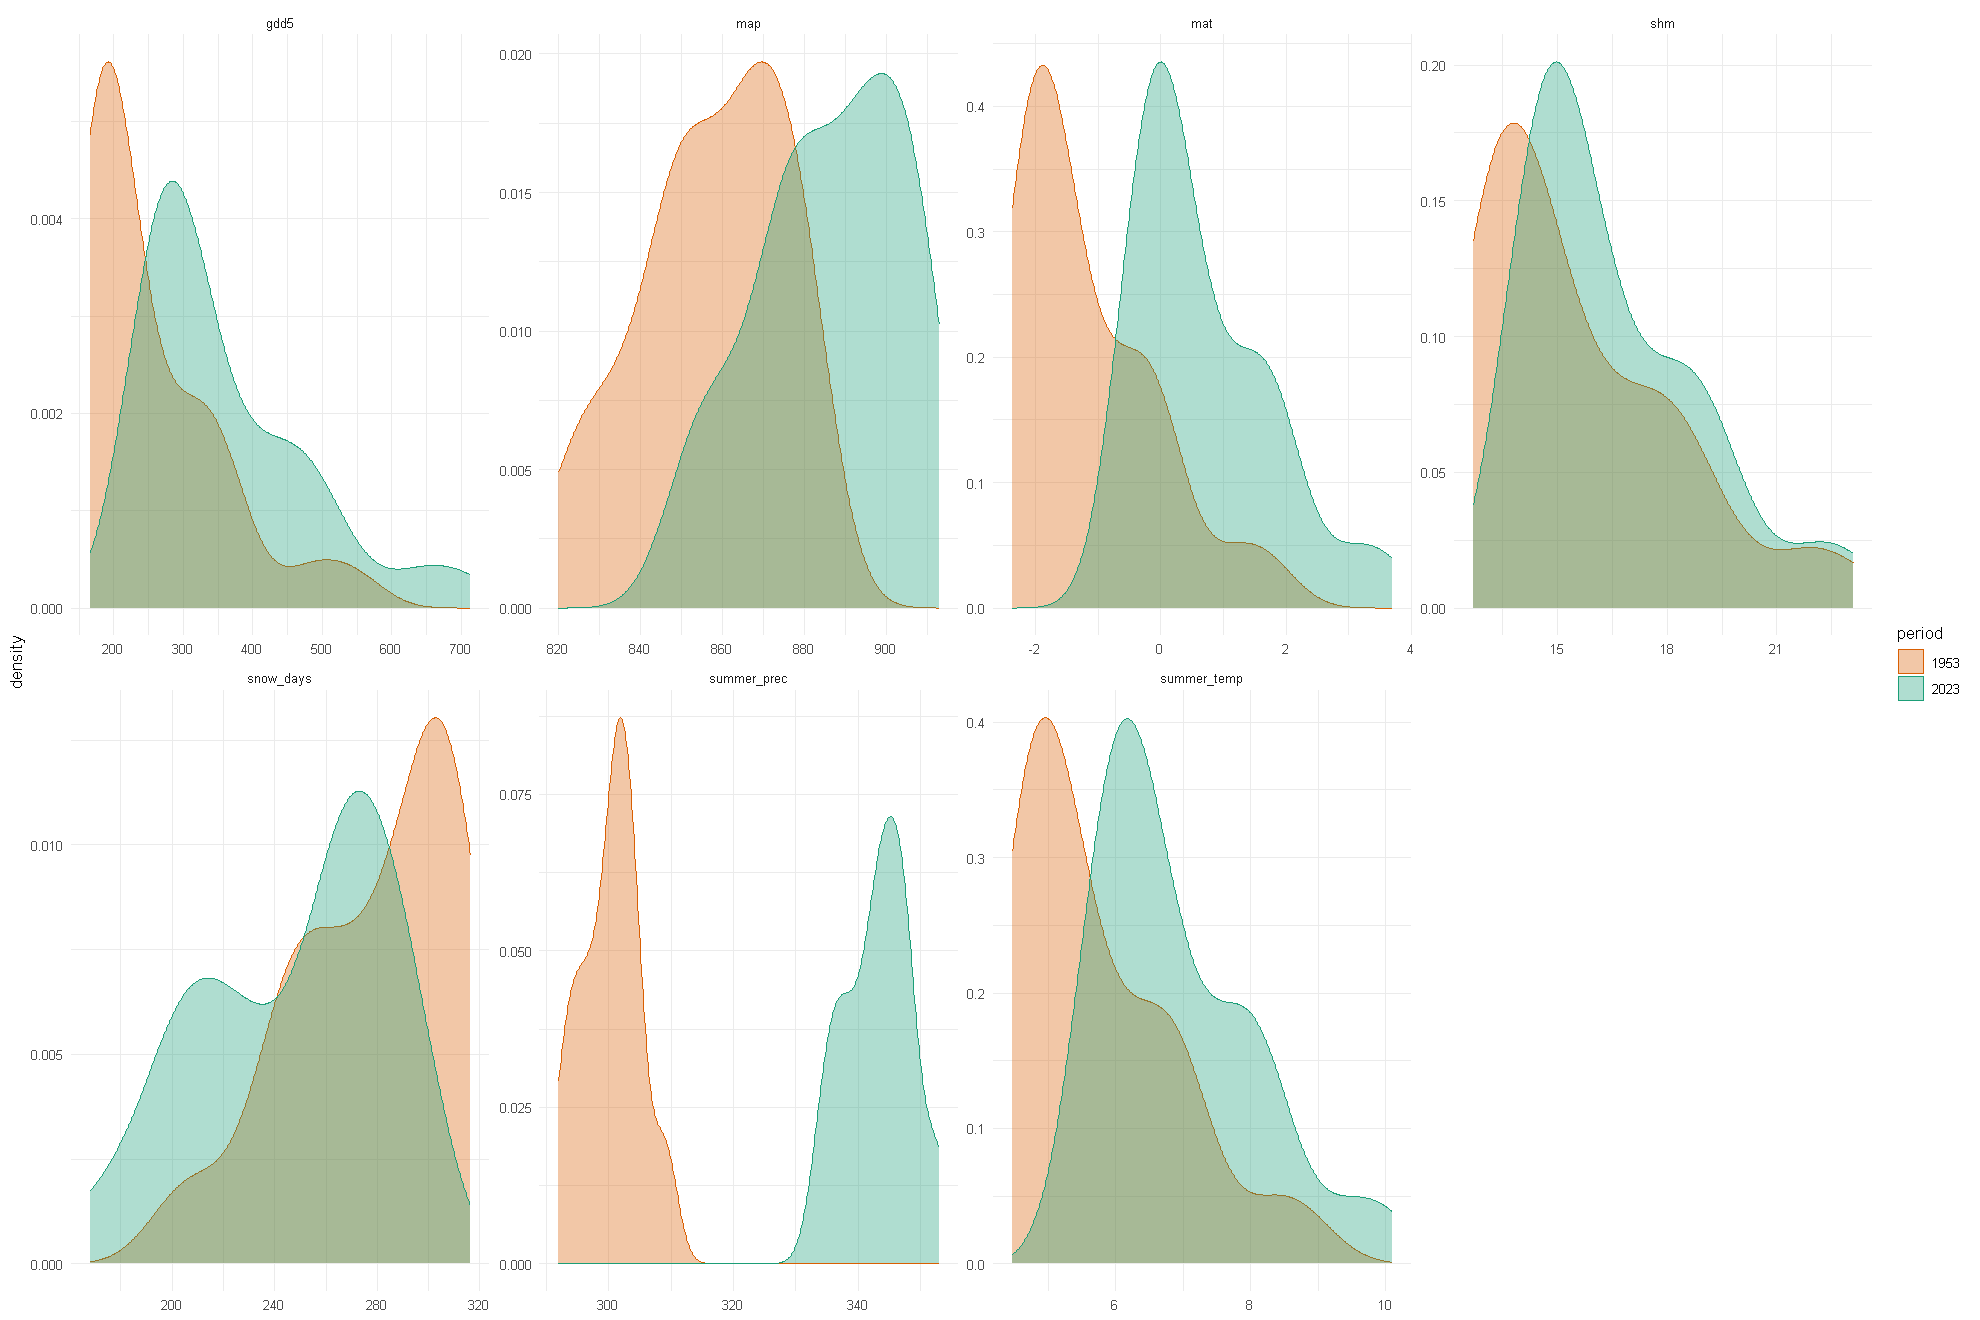

In [14]:
plot_dist(climate)

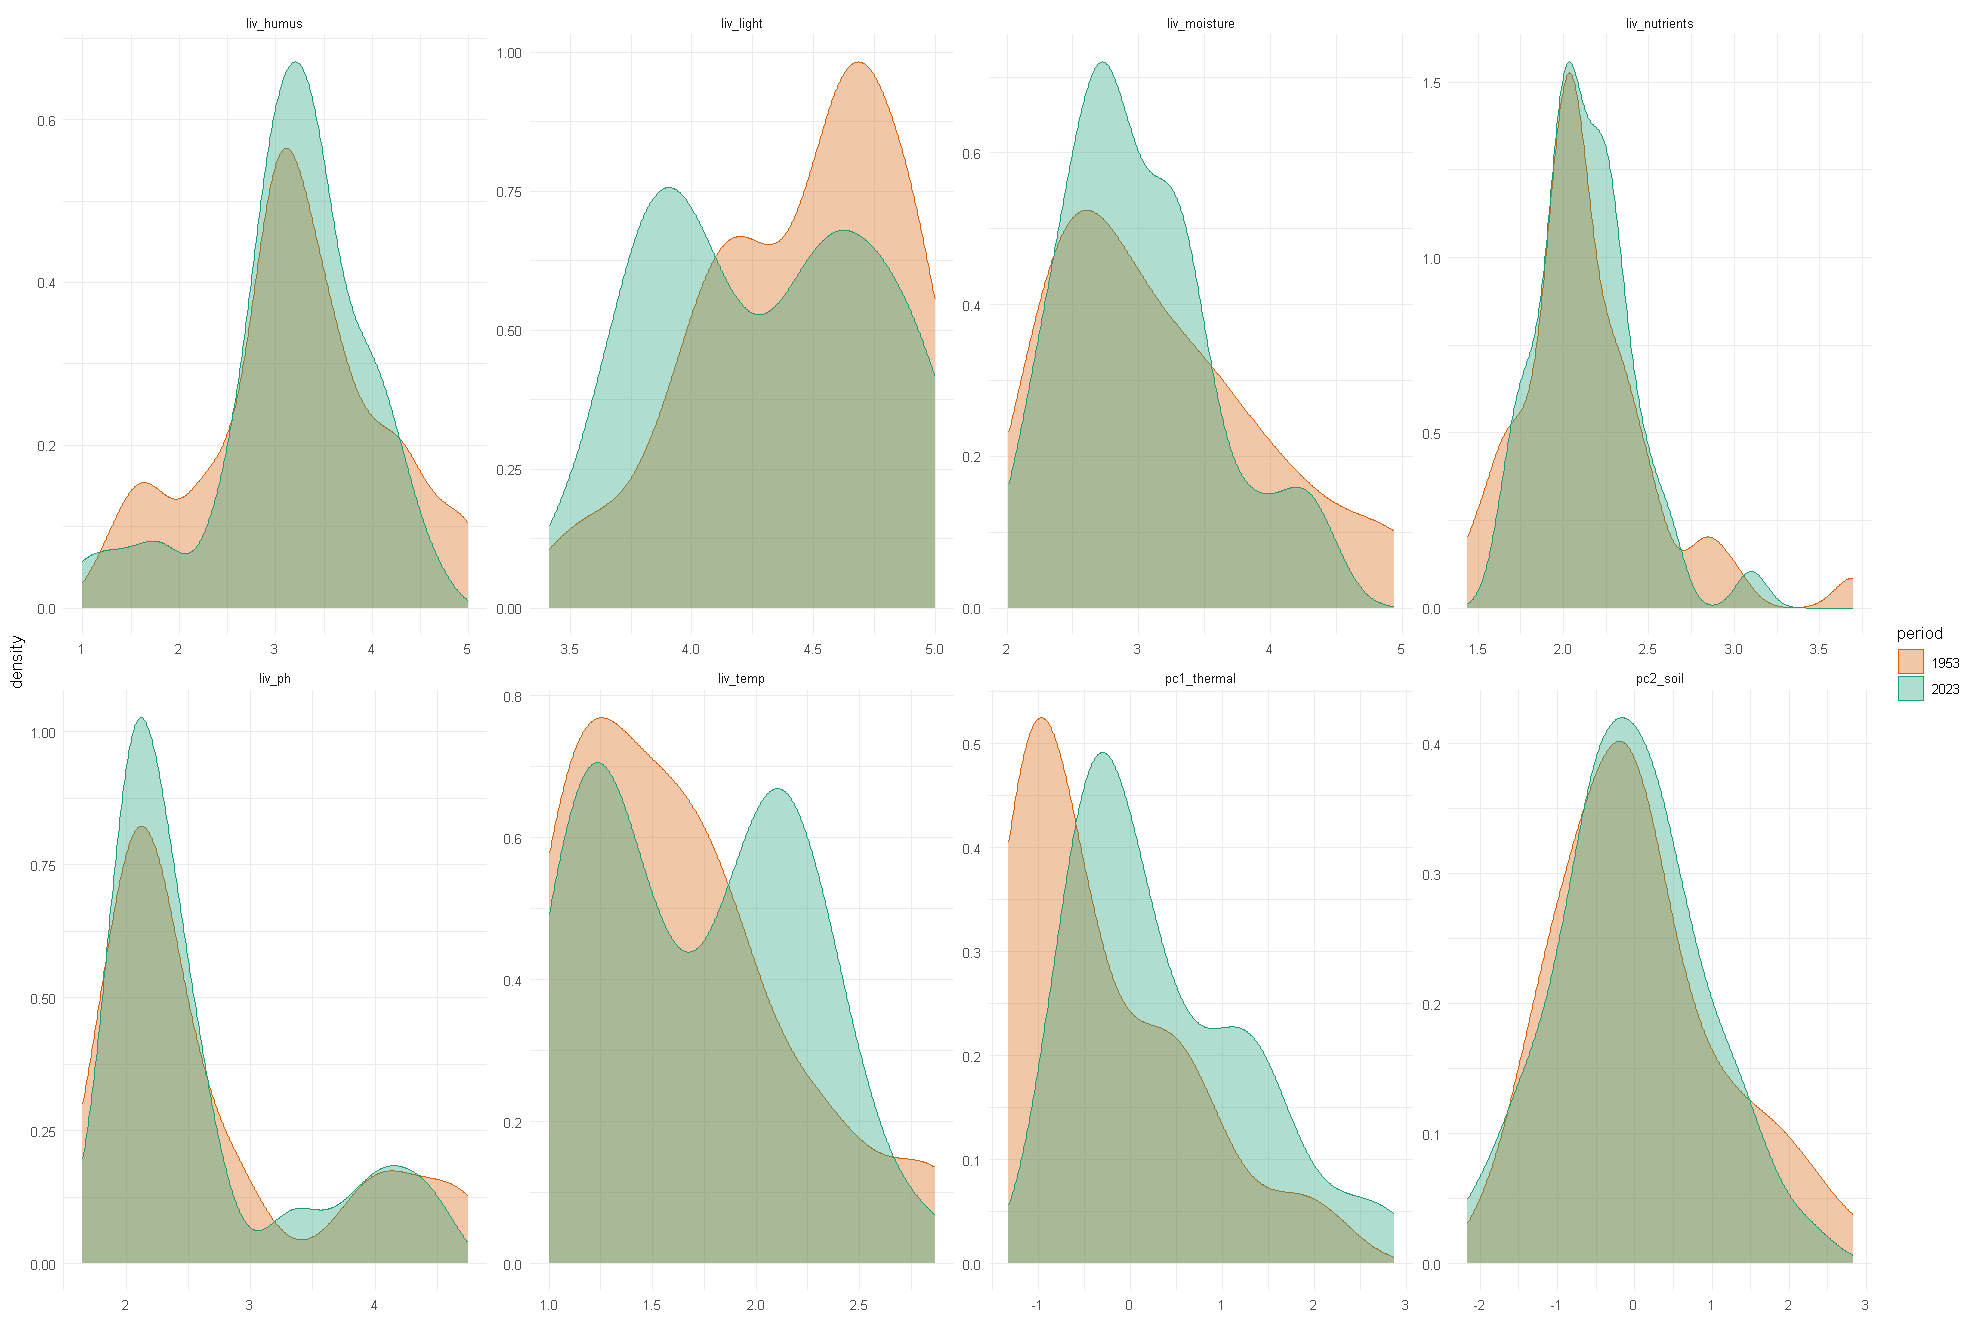

In [15]:
plot_dist(liv)

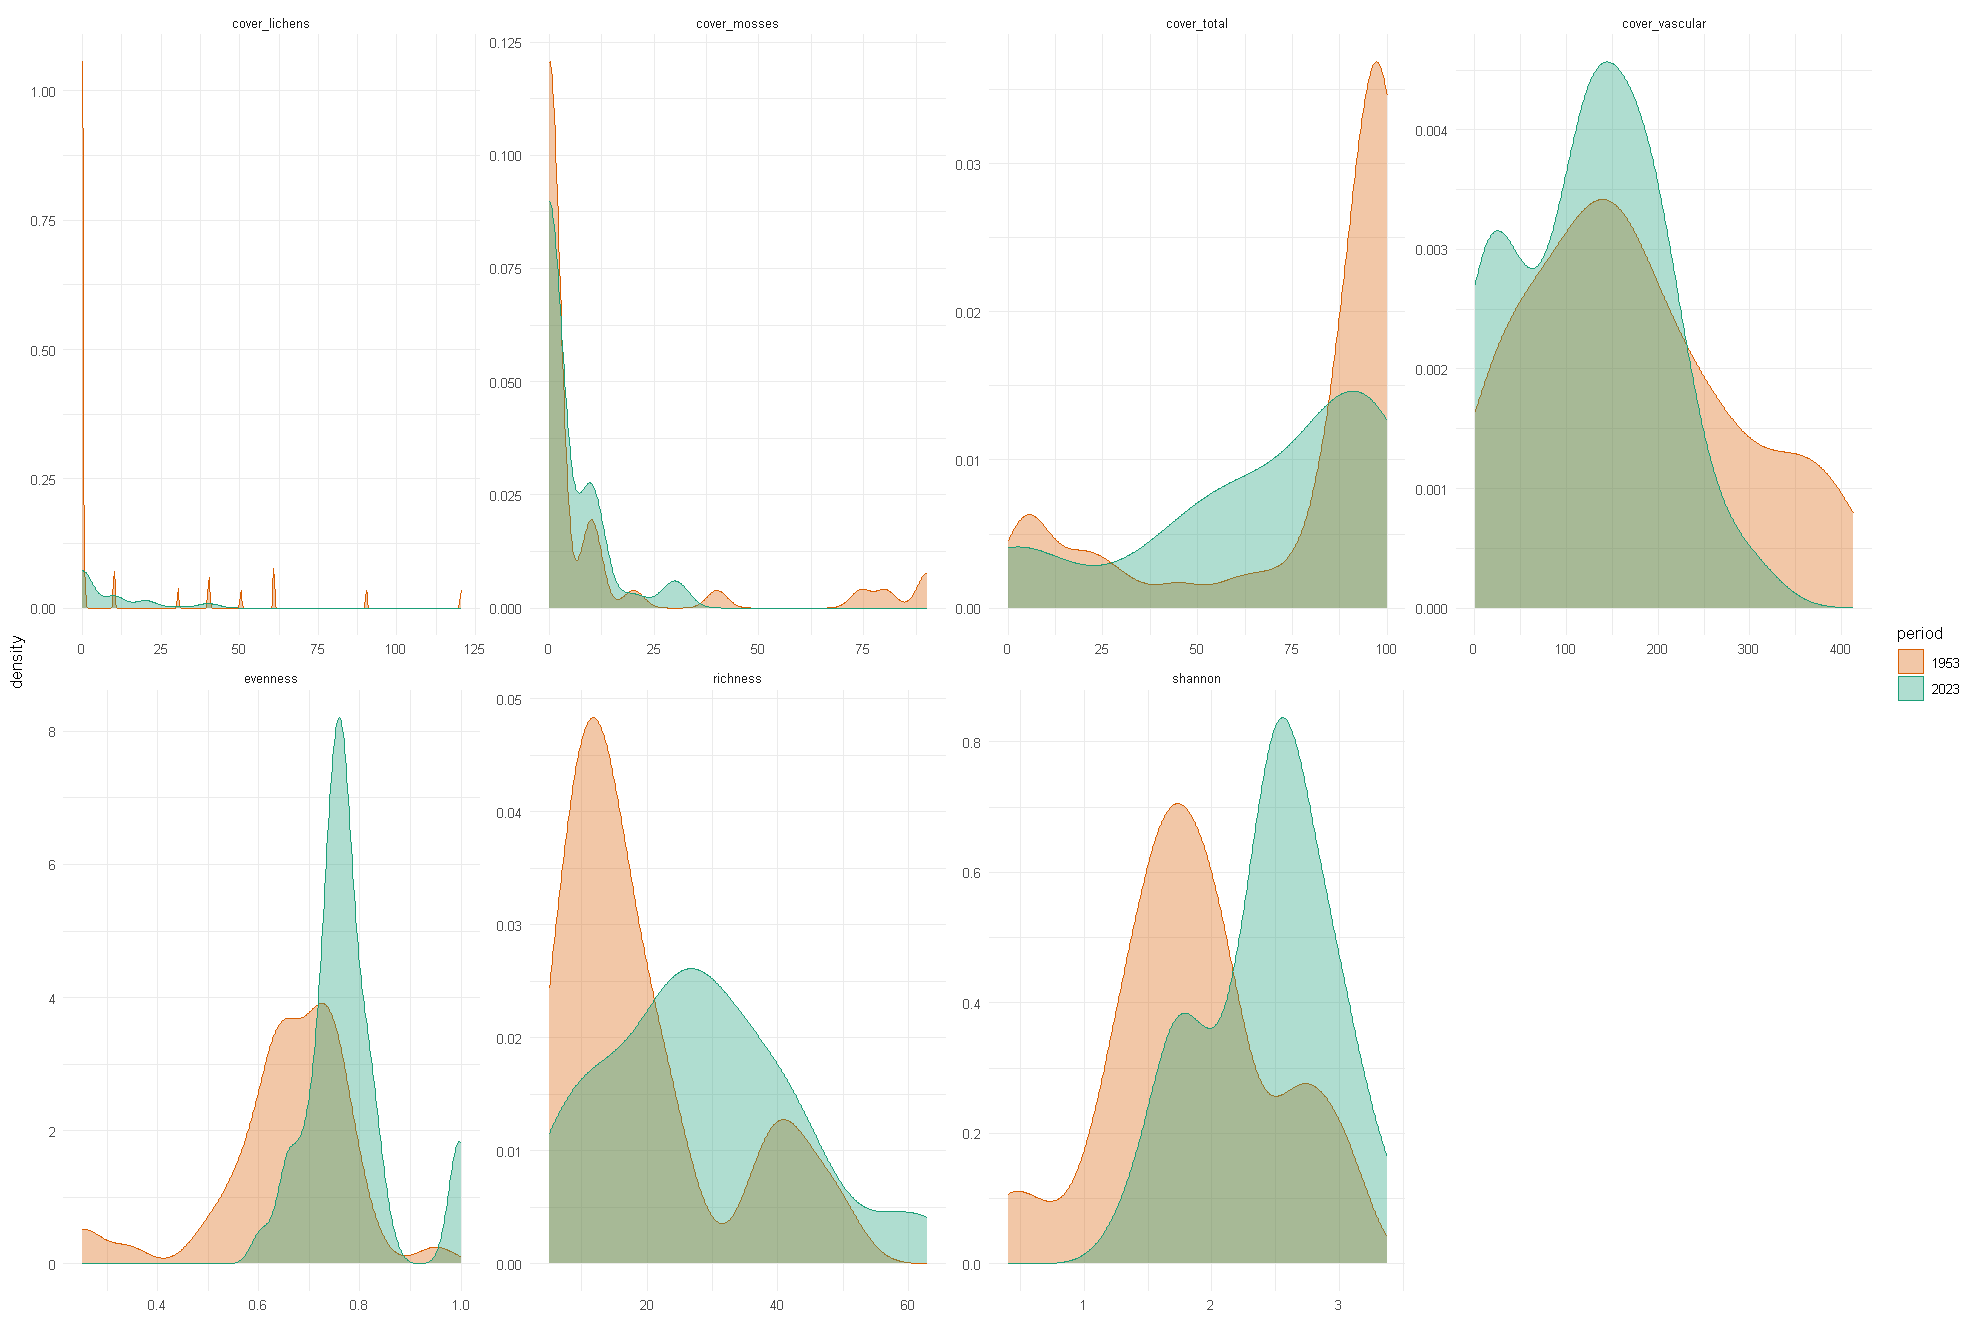

In [16]:
plot_dist(diversity)

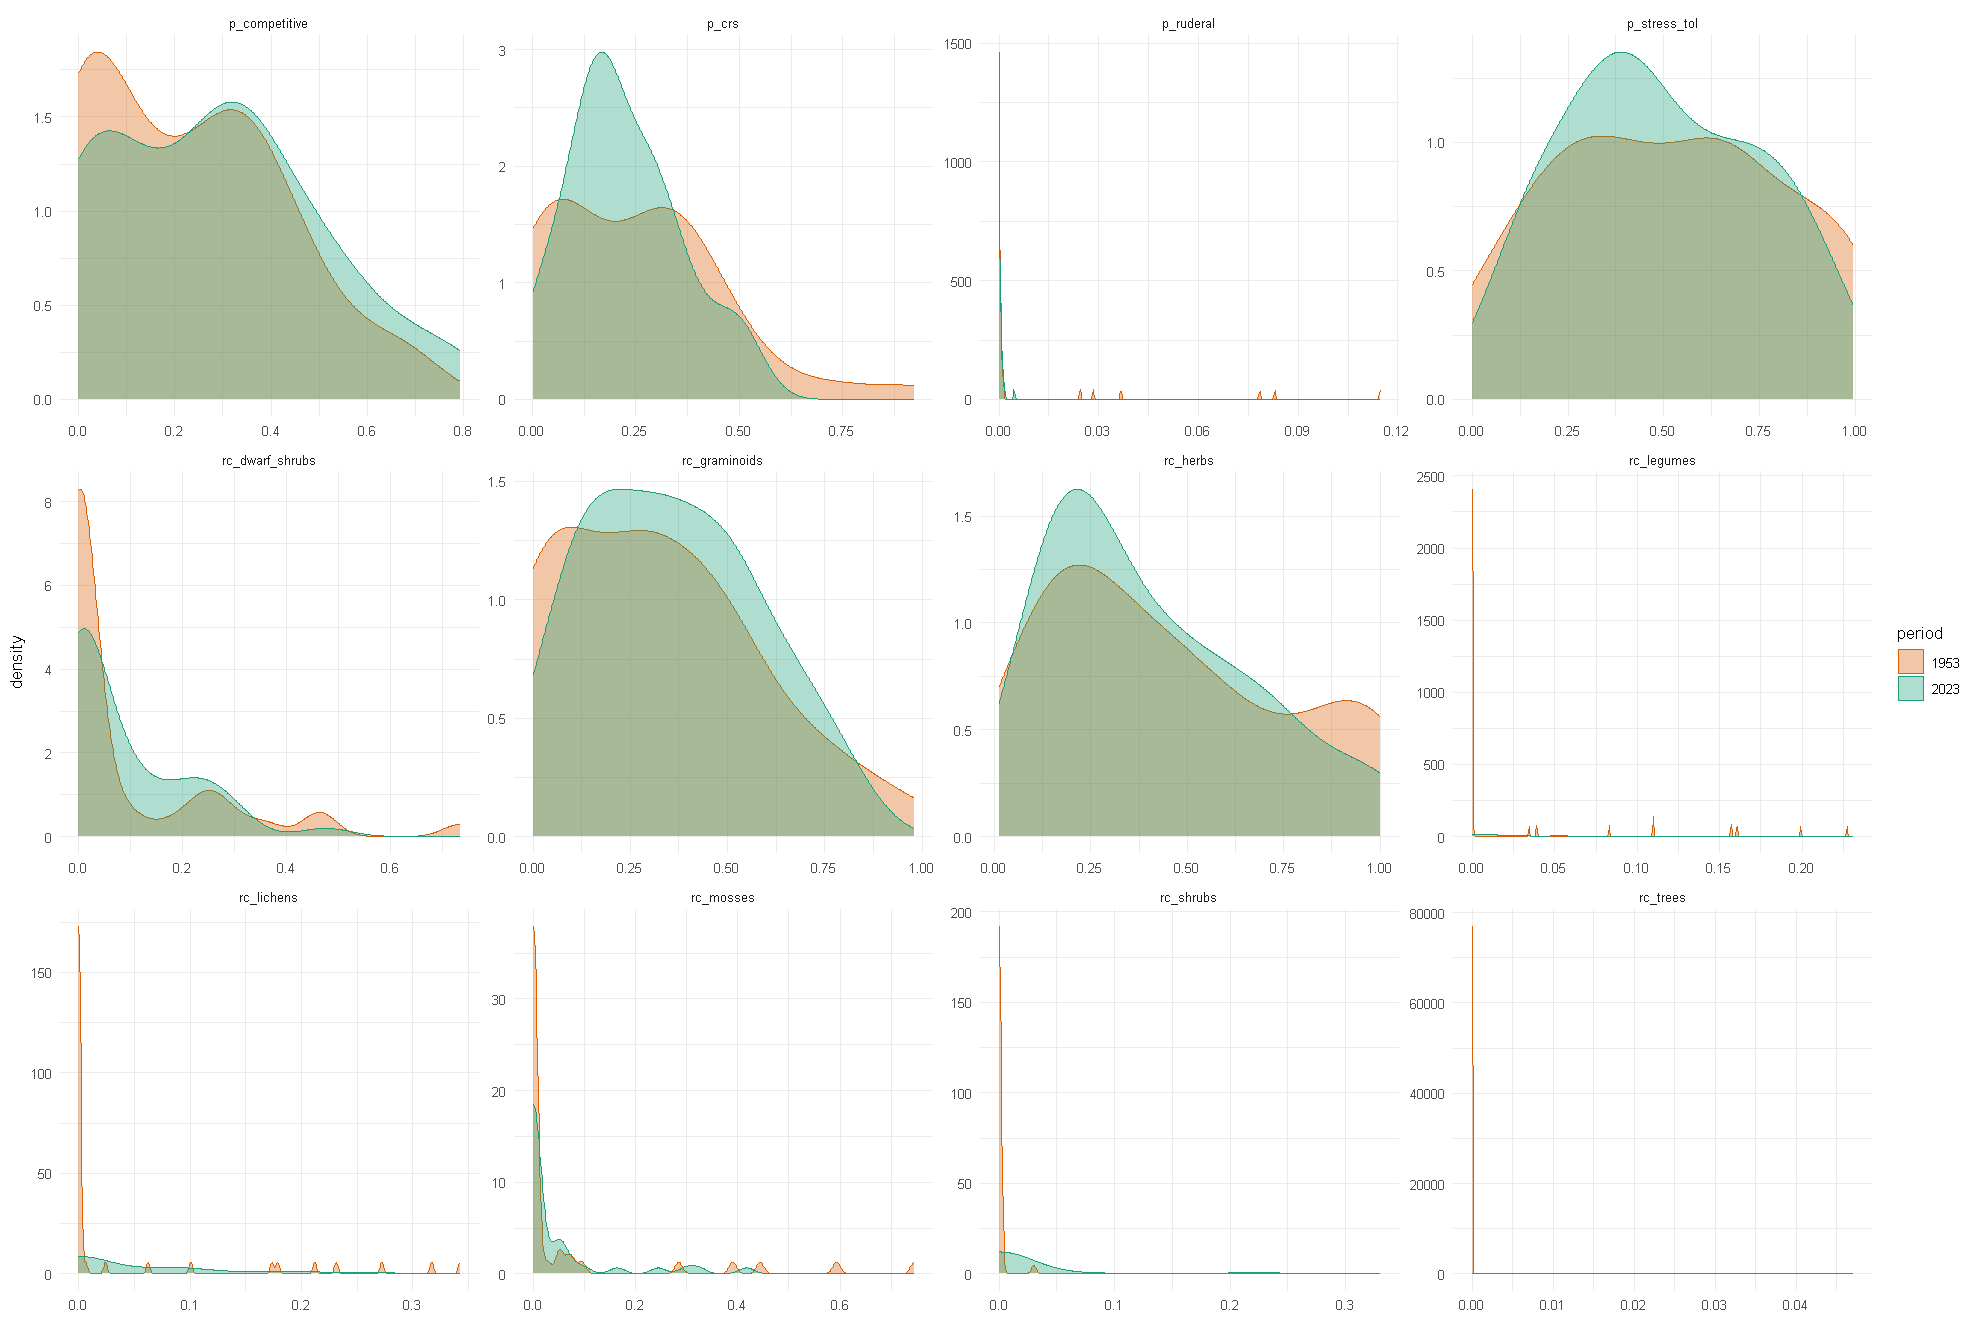

In [17]:
plot_dist(c(growth, strategy), ncol = 4)

## 3.3 Boxplots by period

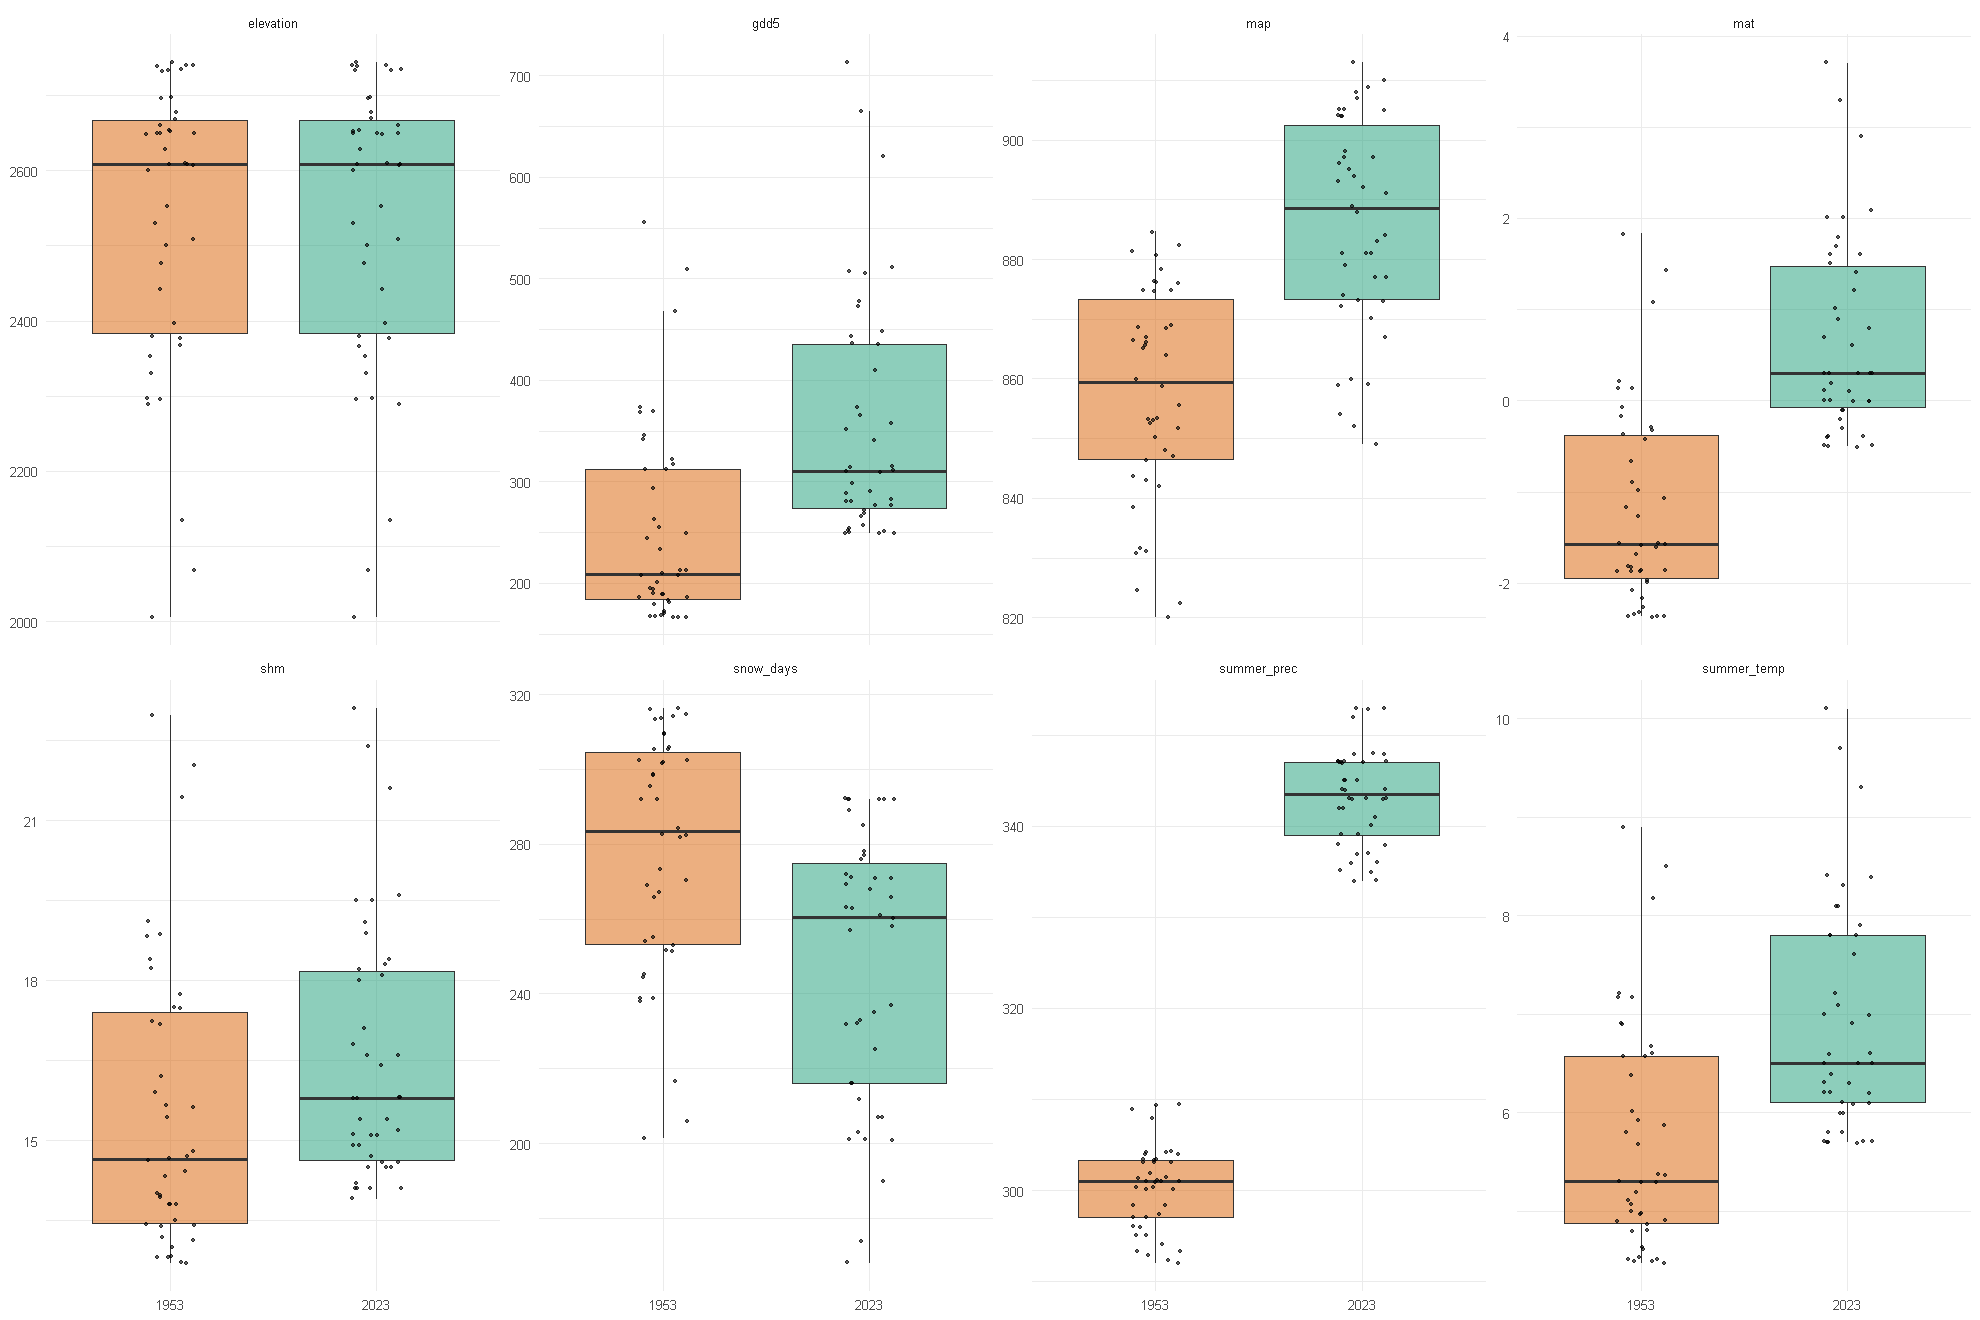

In [18]:
plot_box(c(climate, "elevation"))

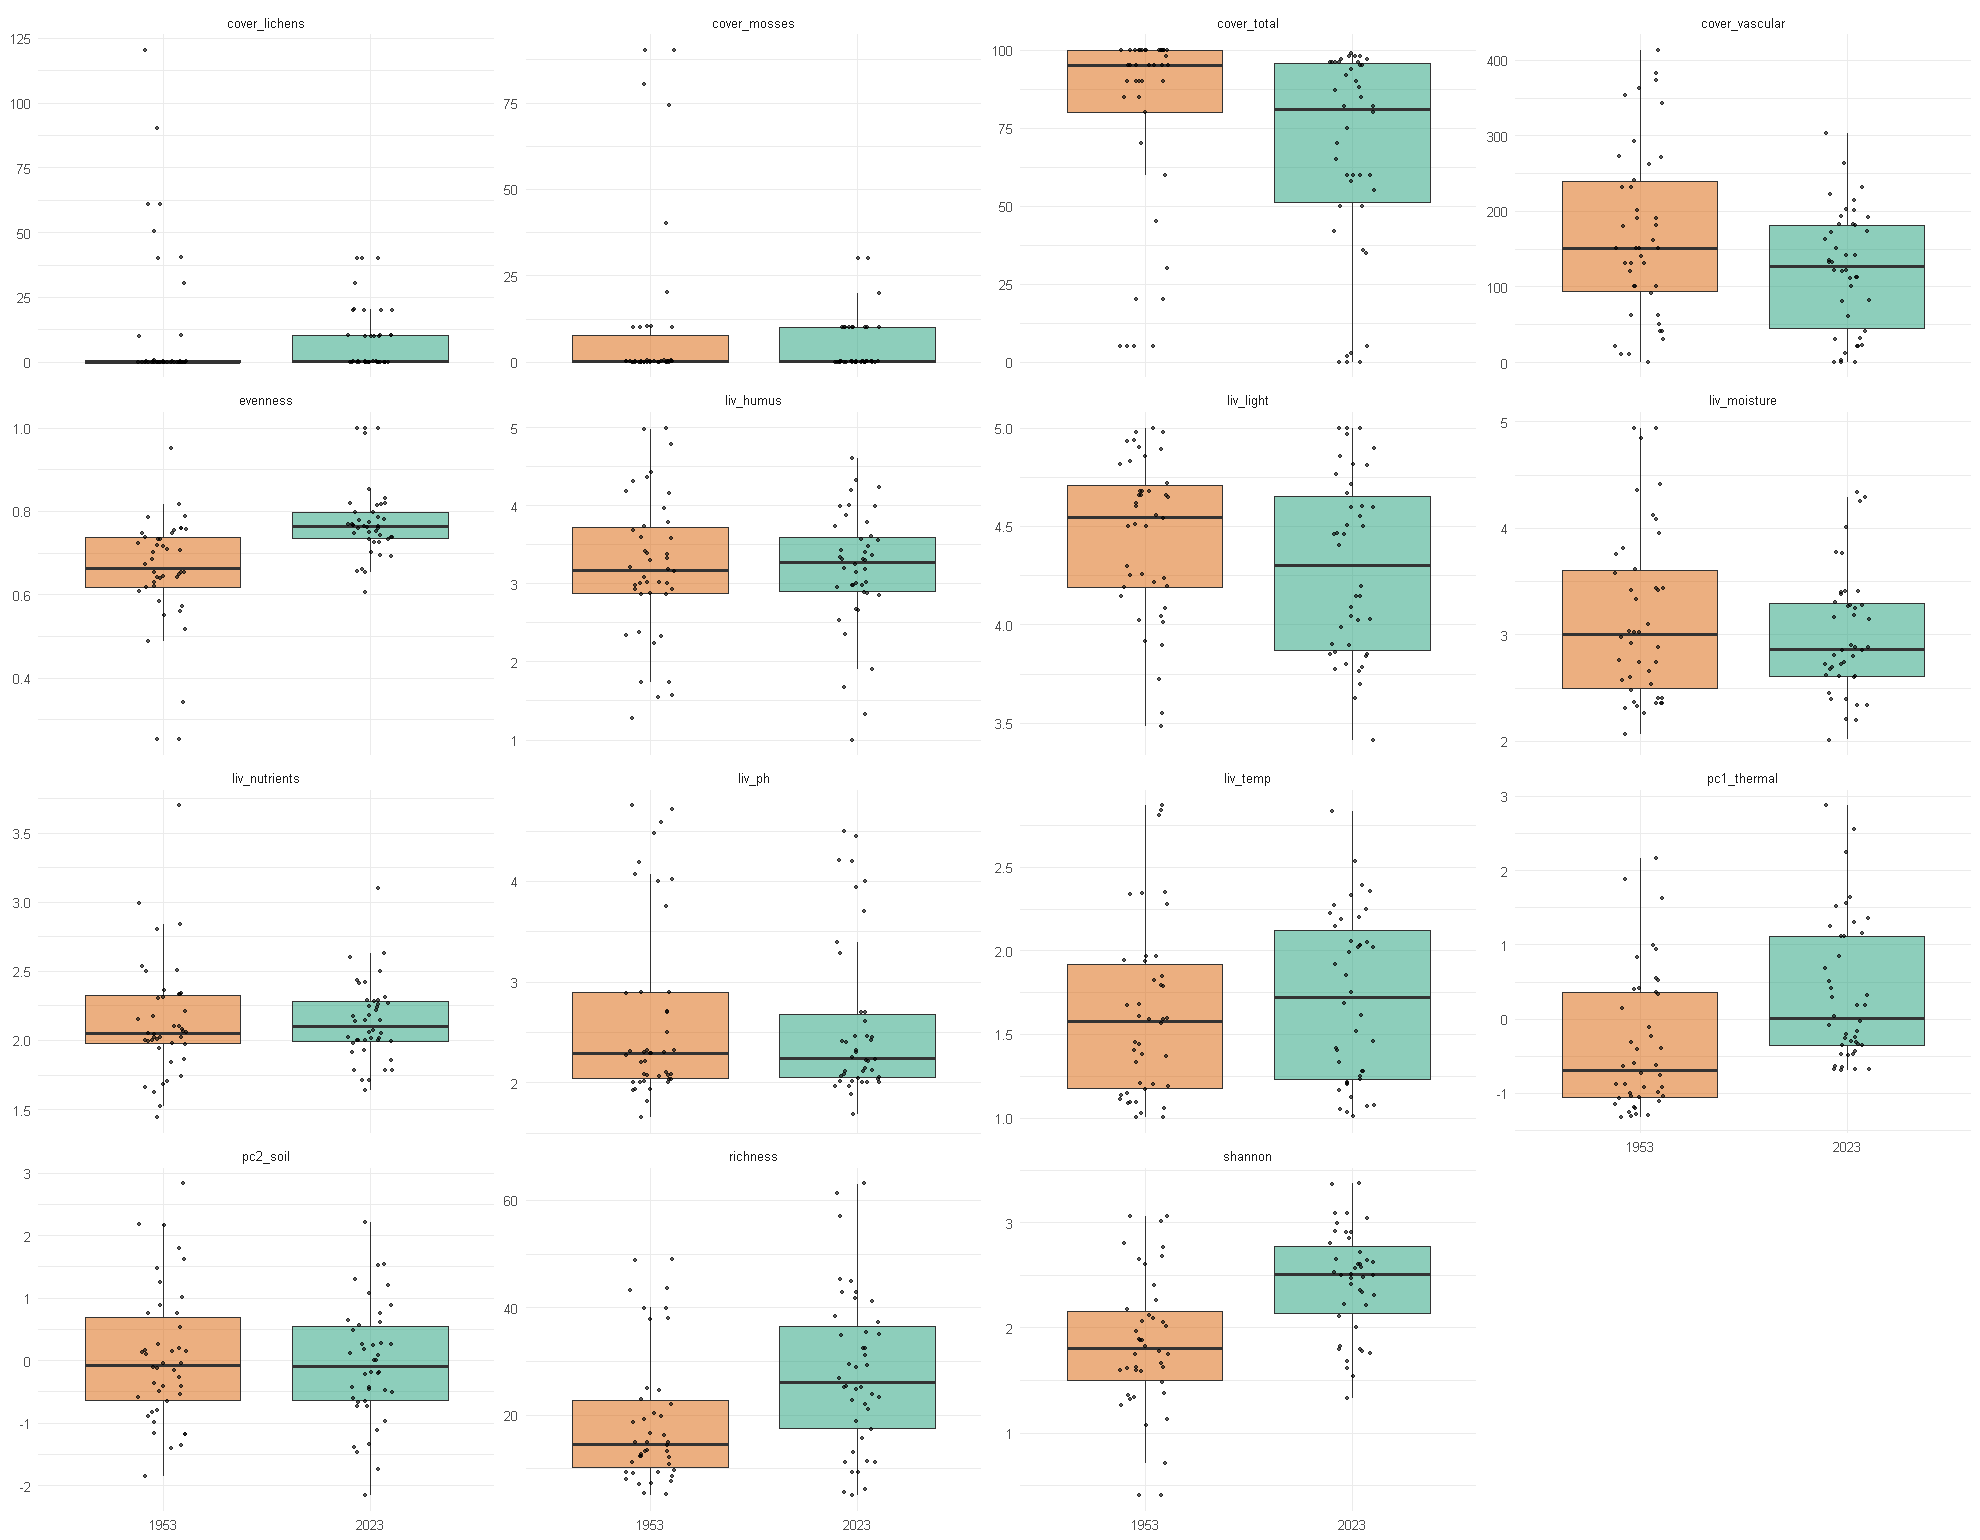

In [19]:
options(repr.plot.width = 18, repr.plot.height = 14)
plot_box(c(liv, diversity))

## 3.4 Categorical variables

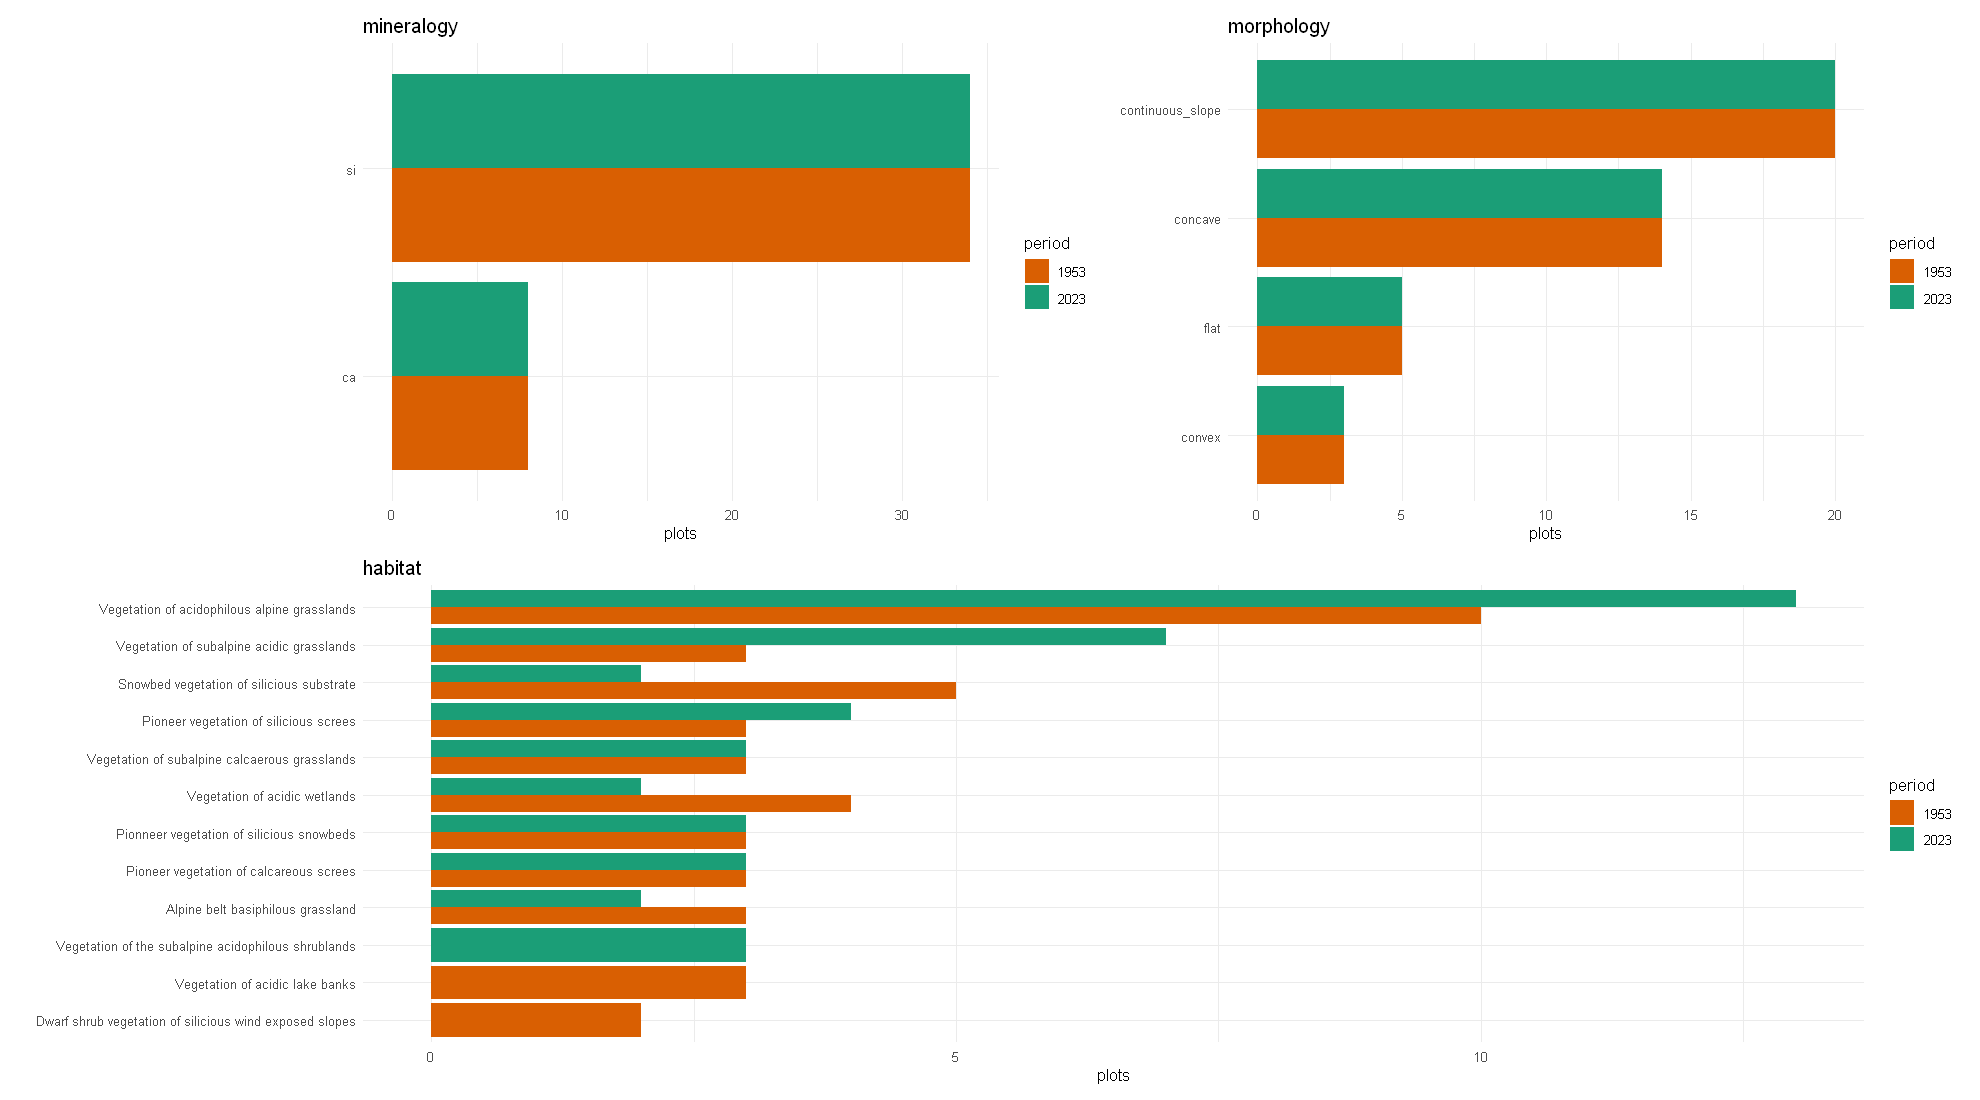

In [20]:
options(repr.plot.width = 18, repr.plot.height = 10)
cat_plot <- function(var) {
  env %>% count(period, .data[[var]]) %>%
    ggplot(aes(n, reorder(.data[[var]], n, sum), fill = period)) +
    geom_col(position = "dodge") + scale_fill_manual(values = period_cols) +
    labs(x = "plots", y = NULL, title = var)
}
(cat_plot("mineralogy") + cat_plot("morphology")) / cat_plot("habitat")

Check how abbreviations map to full association names (inconsistent labels show up as
an abbreviation with several names, or a name with several abbreviations):

In [21]:
env %>% count(assoc_abbr, association) %>% arrange(assoc_abbr) %>% kable()

assoc_abbr,association,n
CC,Caricetum curvulae,6
CF,Caricetum goodenowii,3
CF_D,Caricetum goodenowii degraded,3
CFi,Caricetum firmae,5
DP,Deschampsio cespitosae-Poetum alpinae,5
ES,Eriophoretum scheuchzeri,3
FH,Festucetum halleri,8
FV,Pulsatillo albae-Festucion variae,1
LC,Loiseleurieto-Cetrarietum,2
LC/CC,Loiseleurio-Caricetum curvulae,8


Did the plot's association change between 1953 and 2023?

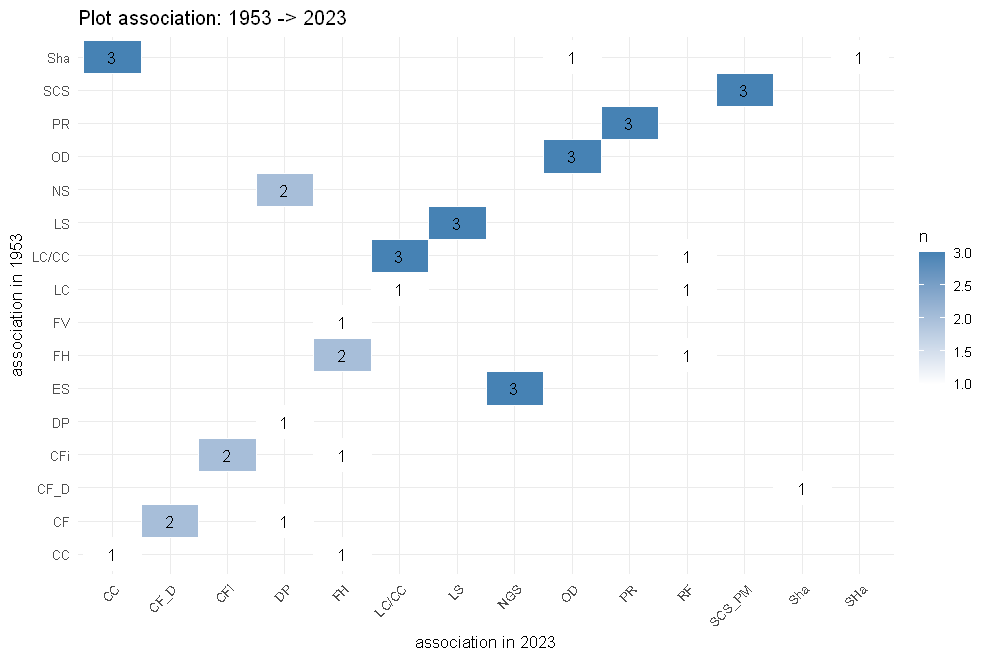

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)
assoc_shift <- env %>%
  filter(base_id %in% paired_ids) %>%
  mutate(assoc_abbr = as.character(assoc_abbr)) %>%
  select(base_id, period, assoc_abbr) %>%
  pivot_wider(names_from = period, values_from = assoc_abbr, names_prefix = "y") %>%
  count(y1953, y2023)

ggplot(assoc_shift, aes(y2023, y1953, fill = n)) +
  geom_tile(colour = "white") + geom_text(aes(label = n)) +
  scale_fill_gradient(low = "white", high = "steelblue") +
  labs(x = "association in 2023", y = "association in 1953",
       title = "Plot association: 1953 -> 2023") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

## 3.5 Spatial layout

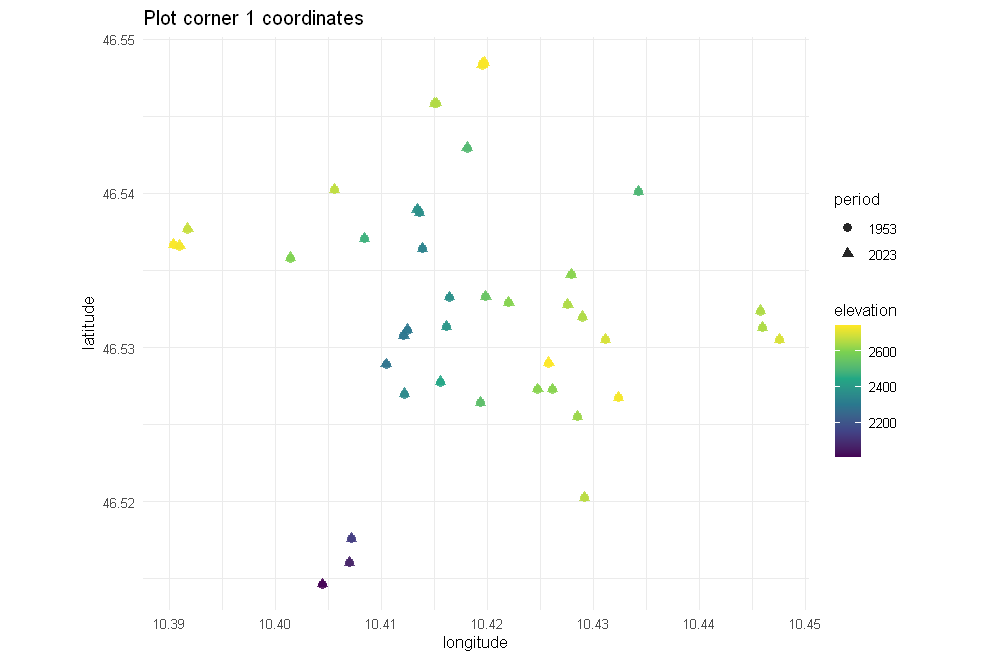

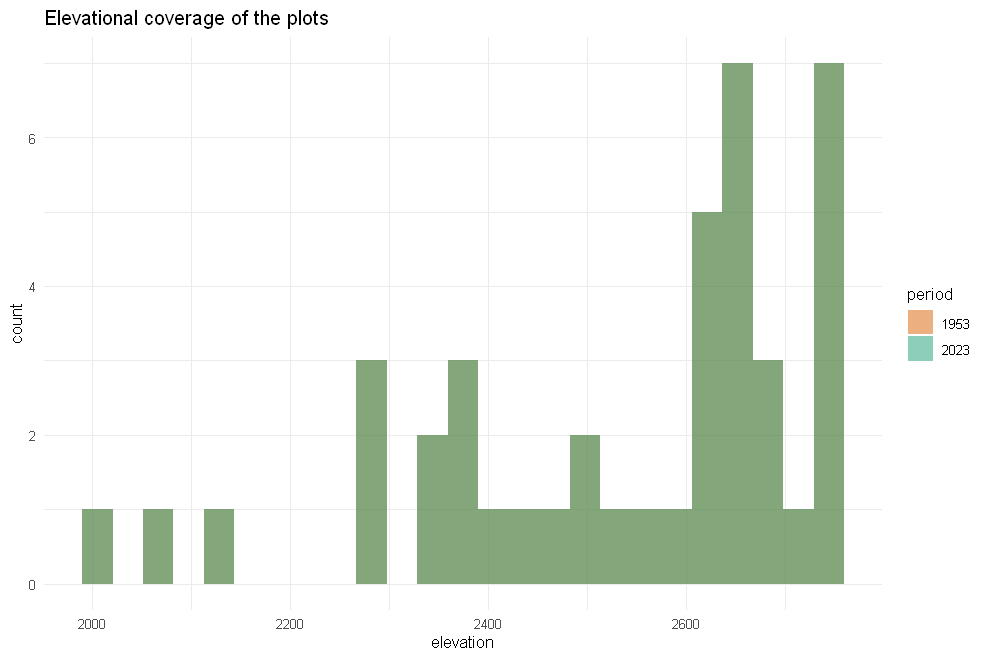

In [23]:
ggplot(env, aes(lon, lat, colour = elevation, shape = period)) +
  geom_point(size = 2.5, alpha = .85) + coord_quickmap() +
  scale_colour_viridis_c() +
  labs(title = "Plot corner 1 coordinates", x = "longitude", y = "latitude")

ggplot(env, aes(elevation, fill = period)) +
  geom_histogram(bins = 25, position = "identity", alpha = .5) +
  scale_fill_manual(values = period_cols) + labs(title = "Elevational coverage of the plots")

## 3.6 Correlations among variables

v1,v2,r
summer_temp,gdd5,1.00
cover_lichens,rc_lichens,0.99
summer_temp,pc1_thermal,0.99
summer_temp,snow_days,-0.98
snow_days,pc1_thermal,-0.98
gdd5,pc1_thermal,0.98
gdd5,snow_days,-0.98
shm,snow_days,-0.98
shm,pc1_thermal,0.97
mat,gdd5,0.96


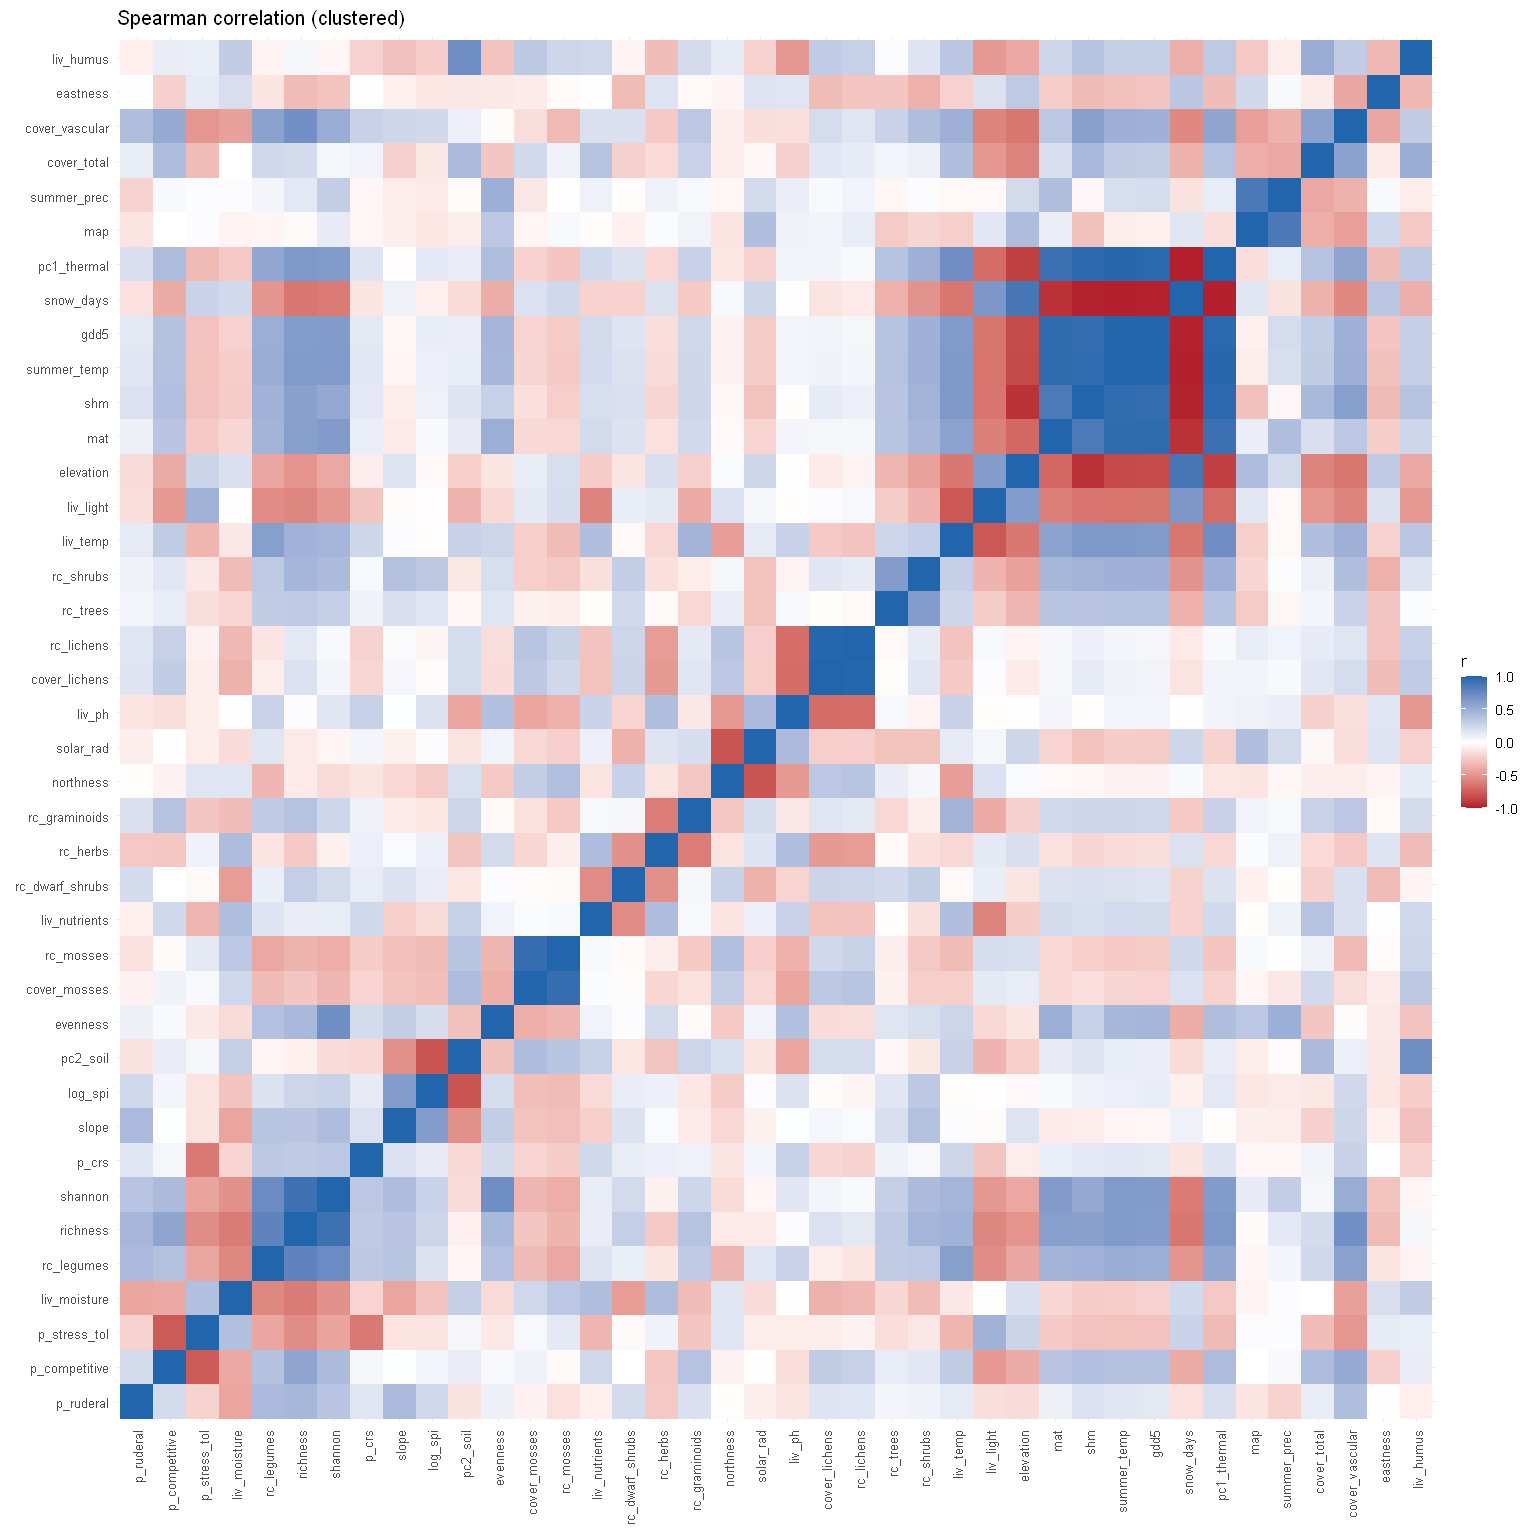

In [24]:
options(repr.plot.width = 14, repr.plot.height = 14)
corr_vars <- setdiff(num_vars, "livestock_units")
cm <- env %>% select(all_of(corr_vars)) %>% cor(use = "pairwise.complete.obs", method = "spearman")
cm[is.na(cm)] <- 0
ord <- hclust(as.dist(1 - abs(cm)))$order
cm_long <- as.data.frame(as.table(cm[ord, ord])) %>% rename(v1 = Var1, v2 = Var2, r = Freq)

ggplot(cm_long, aes(v1, v2, fill = r)) + geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", limits = c(-1, 1)) +
  labs(x = NULL, y = NULL, title = "Spearman correlation (clustered)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5))

cm_long %>% filter(as.integer(v1) < as.integer(v2), abs(r) >= 0.85) %>%
  arrange(desc(abs(r))) %>% mutate(r = round(r, 2)) %>%
  kable(caption = "Highly collinear pairs (|rho| >= 0.85)")

## 3.7 PCA of the environment

,PC1,PC2,PC3,PC4,PC5
Standard deviation,2.678,1.695,1.521,1.438,1.095
Proportion of Variance,0.377,0.151,0.122,0.109,0.063
Cumulative Proportion,0.377,0.529,0.650,0.759,0.822


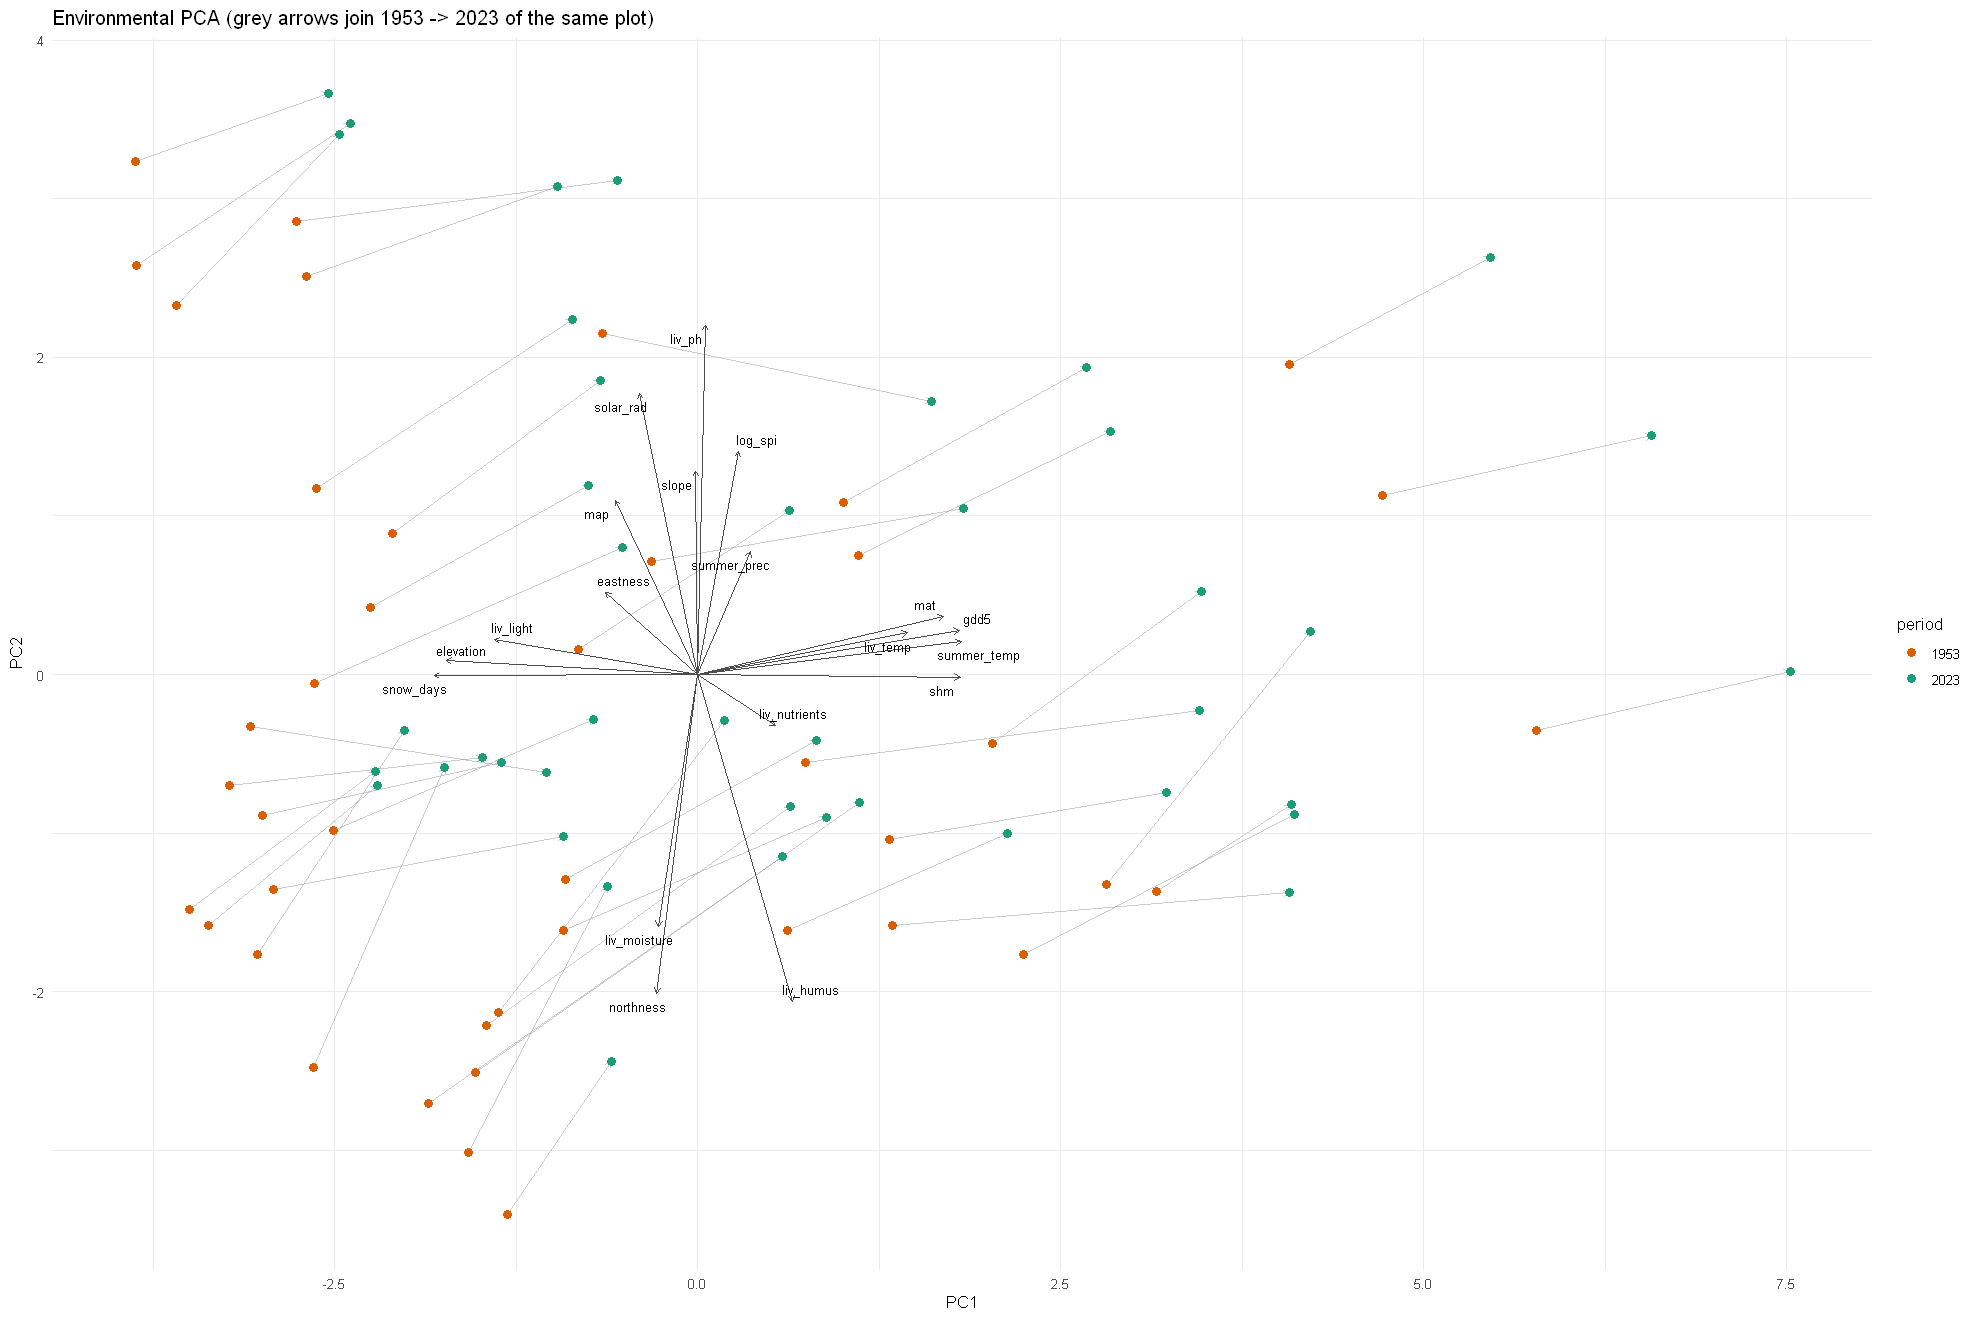

In [25]:
options(repr.plot.width = 18, repr.plot.height = 12)
pca_vars <- c(setdiff(topo, "livestock_units"), climate, liv[1:6])
pca_df <- env %>% select(base_id, plot_id, period, all_of(pca_vars)) %>% drop_na()
pca <- prcomp(pca_df %>% select(all_of(pca_vars)), scale. = TRUE)

round(summary(pca)$importance[, 1:5], 3) %>% kable(caption = "Variance explained")

sc <- bind_cols(pca_df %>% select(base_id, period), as_tibble(pca$x[, 1:2]))
ld <- as_tibble(pca$rotation[, 1:2], rownames = "variable")

ggplot(sc, aes(PC1, PC2)) +
  geom_path(aes(group = base_id), colour = "grey60", alpha = .5,
            arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(aes(colour = period), size = 2.5) +
  geom_segment(data = ld, aes(x = 0, y = 0, xend = PC1 * 5, yend = PC2 * 5),
               colour = "grey30", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_text_repel(data = ld, aes(PC1 * 5, PC2 * 5, label = variable), size = 3) +
  scale_colour_manual(values = period_cols) +
  labs(title = "Environmental PCA (grey arrows join 1953 -> 2023 of the same plot)")

## 3.8 Paired change 1953 -> 2023 (same plot)

In [26]:
options(repr.plot.width = 9, repr.plot.height = 5)
paired <- env %>%
  filter(base_id %in% paired_ids) %>%
  select(base_id, period, all_of(num_vars)) %>%
  pivot_longer(-c(base_id, period), names_to = "name") %>%
  pivot_wider(names_from = period, values_from = value, names_prefix = "y")

paired_tests <- paired %>%
  group_by(name) %>%
  group_modify(~ {
    d <- .x %>% filter(!is.na(y1953), !is.na(y2023))
    out <- tibble(n = nrow(d), mean_1953 = NA_real_, mean_2023 = NA_real_,
                  mean_diff = NA_real_, median_diff = NA_real_, p = NA_real_)
    if (nrow(d) >= 5) {
      out$mean_1953   <- mean(d$y1953)
      out$mean_2023   <- mean(d$y2023)
      out$mean_diff   <- mean(d$y2023 - d$y1953)
      out$median_diff <- median(d$y2023 - d$y1953)
      if (any(d$y2023 != d$y1953)) {
        out$p <- suppressWarnings(wilcox.test(d$y2023, d$y1953, paired = TRUE)$p.value)
      }
    }
    out
  }) %>%
  ungroup() %>%
  mutate(p_adj = p.adjust(p, "BH")) %>%
  arrange(p_adj)

paired_tests %>% mutate(across(where(is.numeric), ~ signif(.x, 3)))
write_csv(paired_tests, "outputs/env_paired_tests.csv")

name,n,mean_1953,mean_2023,mean_diff,median_diff,p,p_adj
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
pc1_thermal,42,-3.47e-01,3.47e-01,6.94e-01,7.02e-01,4.55e-13,1.59e-11
shannon,42,1.85e+00,2.44e+00,5.89e-01,5.96e-01,1.46e-09,2.56e-08
evenness,42,6.54e-01,7.75e-01,1.21e-01,1.07e-01,6.73e-09,5.43e-08
gdd5,42,2.52e+02,3.59e+02,1.07e+02,1.02e+02,1.71e-08,5.43e-08
livestock_units,42,3.08e+02,6.41e+01,-2.44e+02,-3.08e+02,5.60e-09,5.43e-08
map,42,8.58e+02,8.86e+02,2.84e+01,2.87e+01,1.59e-08,5.43e-08
mat,42,-1.19e+00,6.86e-01,1.88e+00,1.87e+00,8.47e-09,5.43e-08
shm,42,1.56e+01,1.65e+01,9.72e-01,1.08e+00,1.70e-08,5.43e-08
snow_days,42,2.78e+02,2.48e+02,-3.05e+01,-2.98e+01,1.70e-08,5.43e-08


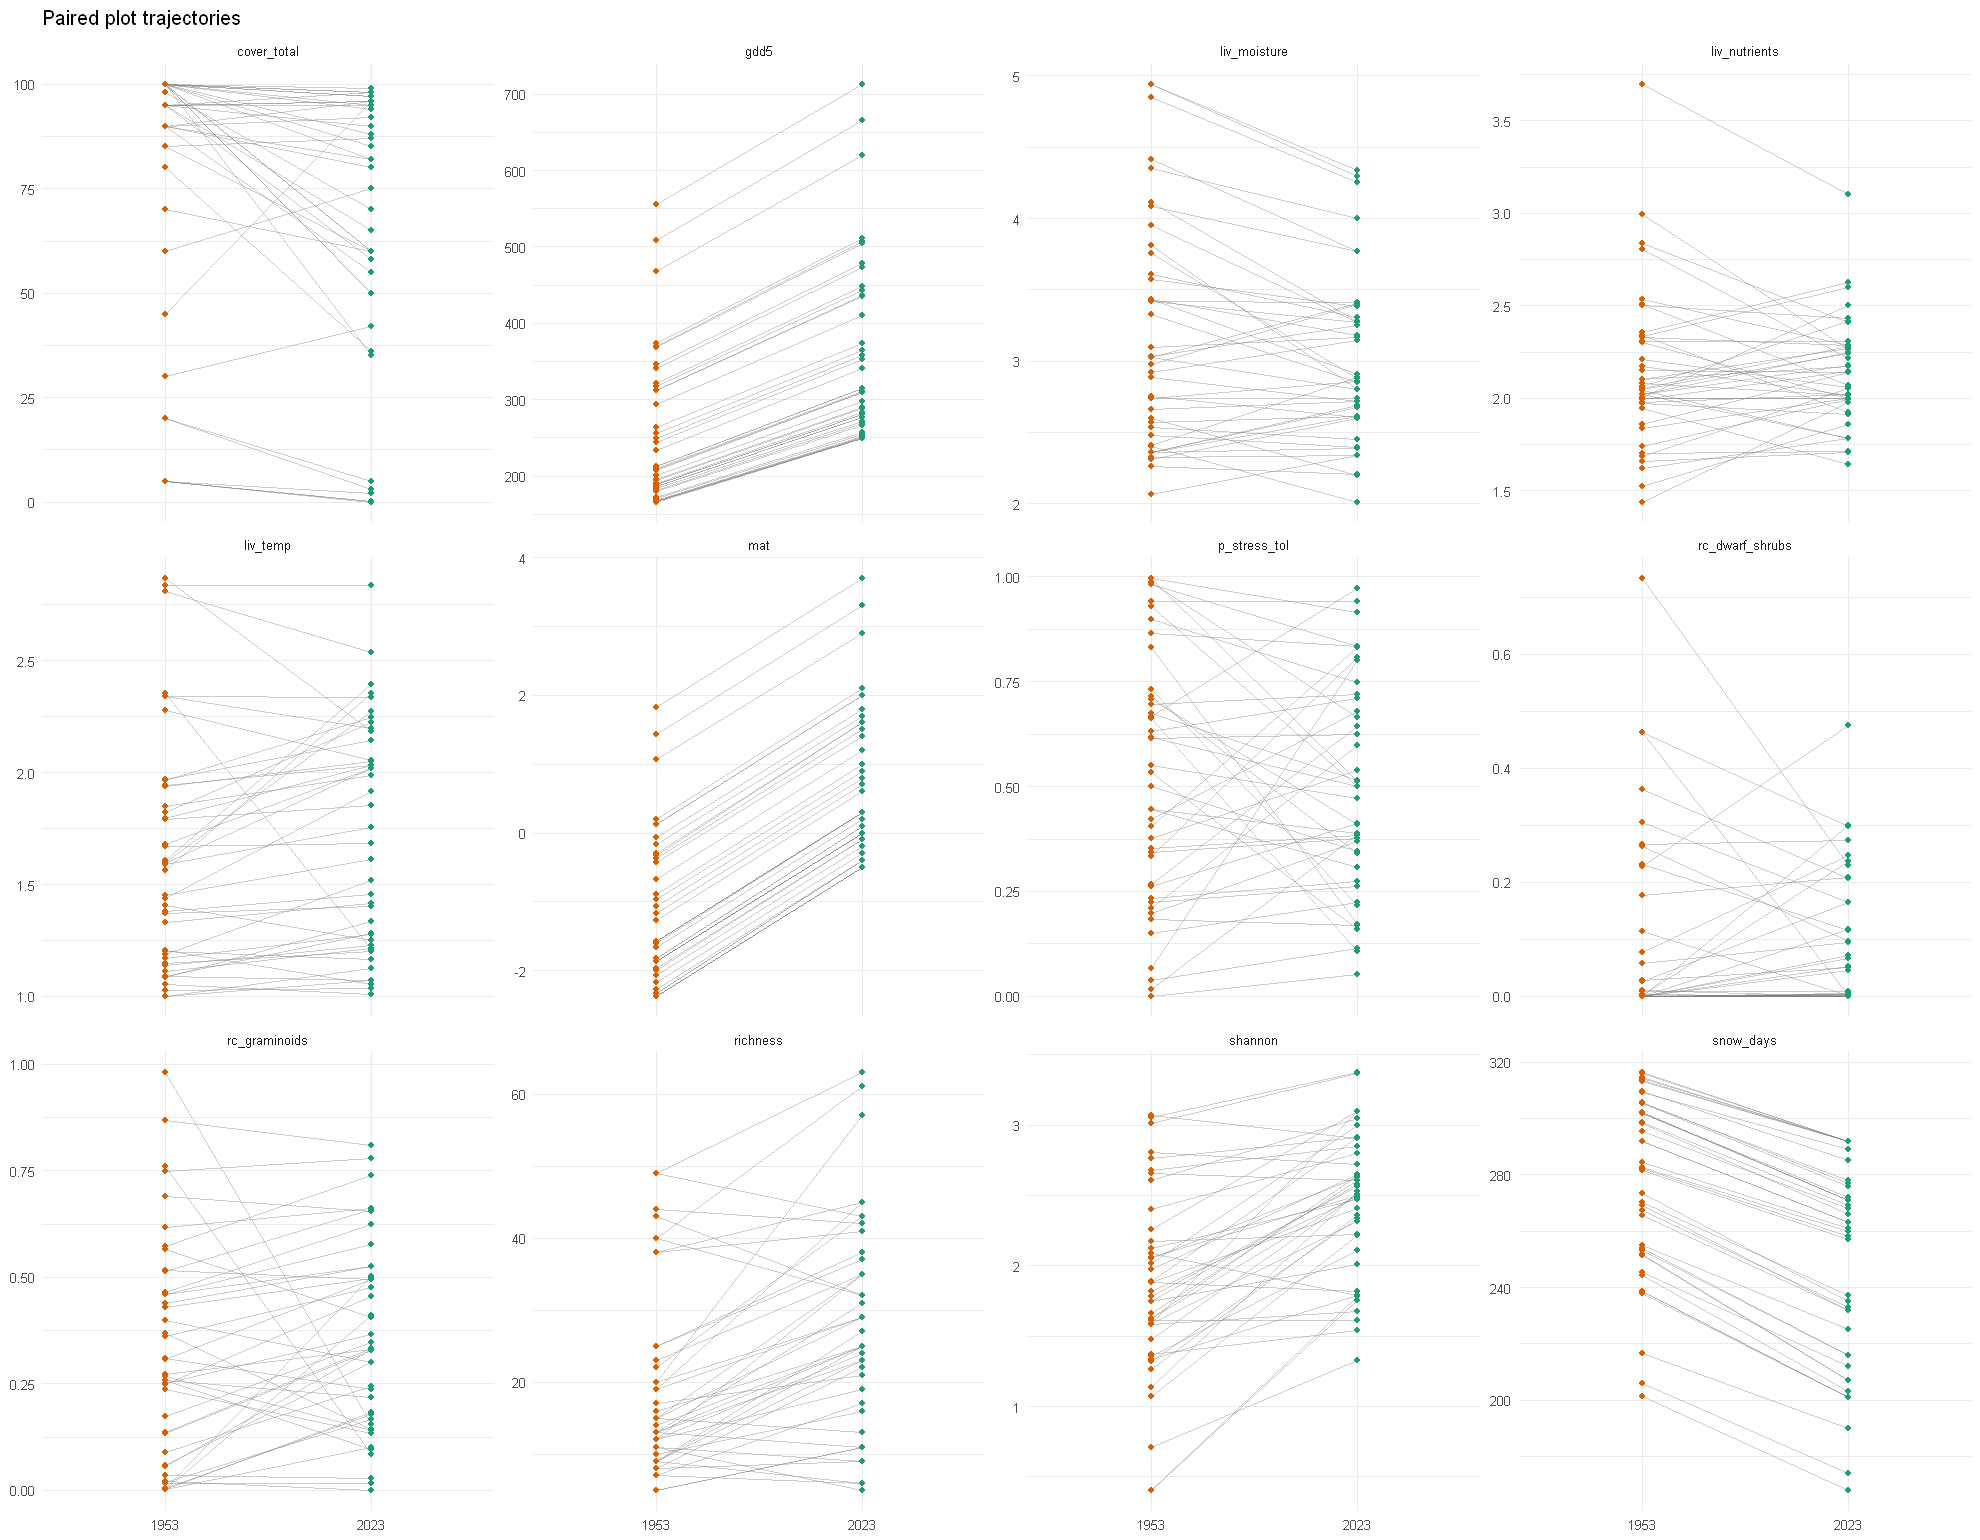

In [27]:
options(repr.plot.width = 18, repr.plot.height = 14)
key_vars <- c("richness", "cover_total", "shannon", "mat", "snow_days", "gdd5",
              "liv_temp", "liv_nutrients", "liv_moisture", "p_stress_tol", "rc_graminoids", "rc_dwarf_shrubs")
paired %>% filter(name %in% key_vars) %>%
  pivot_longer(c(y1953, y2023), names_to = "period", values_to = "value") %>%
  mutate(period = str_remove(period, "y")) %>%
  ggplot(aes(period, value, group = base_id)) +
  geom_line(alpha = .4, colour = "grey50", na.rm = TRUE) +
  geom_point(aes(colour = period), na.rm = TRUE) +
  facet_wrap(~ name, scales = "free_y", ncol = 4) +
  scale_colour_manual(values = period_cols) + guides(colour = "none") +
  labs(x = NULL, y = NULL, title = "Paired plot trajectories")

# 4. Species data

## 4.1 Cover values: what is actually in the table?

The README says cover classes were converted to mean values (r = 0.02, + = 0.1, 1 = 10, 2 = 30,
3 = 50, 4 = 70, 5 = 90). Anything outside that set deserves a look.

In [28]:
options(repr.plot.width = 9, repr.plot.height = 5)
sp_long_raw <- sp %>%
  pivot_longer(
    cols = -plot_id,
    names_to = "taxon",
    values_to = "cover"
  ) %>%
  filter(cover > 0)

sp_long_raw %>% count(cover) %>% mutate(standard = cover %in% c(0.02, 0.1, 10, 30, 50, 70, 90)) %>%
  kable(caption = "Frequency of each non-zero cover value")

sp_long_raw %>% filter(!cover %in% c(0.02, 0.1, 10, 30, 50, 70, 90)) %>%
  arrange(cover) %>% kable(caption = "Non-standard cover values (plot x taxon)")

cover,n,standard
0.02,149,TRUE
0.10,1221,TRUE
0.12,1,FALSE
0.20,116,FALSE
2.00,1,FALSE
10.00,489,TRUE
10.10,3,FALSE
30.00,147,TRUE
30.10,1,FALSE
40.00,1,FALSE


plot_id,taxon,cover
202,Phyteuma betonicifolium,0.12
12,Moehringia ciliata,0.20
17,Poa alpina,0.20
33,Sanionia uncinata,0.20
35,Euphrasia minima agg.,0.20
36,Homogyne alpina,0.20
36,Luzula alpinopilosa,0.20
43,Alchemilla pentaphyllea,0.20
43,Anthelia juratzkana,0.20
43,Sibbaldia procumbens,0.20


In [29]:
cat("Matrix:", nrow(comm), "plots x", ncol(comm), "taxa\n")
cat("Share of zeros:", round(100 * mean(comm == 0), 1), "%\n")
cat("Taxa present in exactly 1 plot:", sum(colSums(comm > 0) == 1), "\n")
cat("Taxa present in <= 3 plots:", sum(colSums(comm > 0) <= 3), "\n")
cat("Taxa never recorded (all zero):", sum(colSums(comm > 0) == 0), "\n")

Matrix: 83 plots x 373 taxa
Share of zeros: 92.9 %
Taxa present in exactly 1 plot: 108 
Taxa present in <= 3 plots: 196 
Taxa never recorded (all zero): 0 


## 4.2 Taxa list: resolution and vascular / non-vascular

There is no growth-group column in the species table, so I flag mosses and lichens by genus.
**Please review the genus list** (the richness check below will reveal mismatches).

In [30]:
nonvasc_genera <- c("Alectoria", "Anthelia", "Arctoa", "Barbilophozia", "Bartramia", "Brachythecium",
  "Bryoerythrophyllum", "Bryum", "Cetraria", "Cladonia", "Climacium", "Cynodontium", "Dicranum",
  "Drepanocladus", "Flavocetraria", "Hylocomium", "Hypnum", "Lescuraea", "Lobaria", "Nephromopsis",
  "Ochrolechia", "Oncophorus", "Paraleucobryum", "Peltigera", "Philonotis", "Plagiothecium",
  "Pleuroclada", "Polytrichastrum", "Polytrichum", "Ptychostomum", "Racomitrium", "Sanionia",
  "Sarmentypnum", "Scapania", "Solorina", "Stereocaulon", "Syntrichia", "Thamnolia", "Tortella",
  "Tortula", "Webera", "Weissia")
nonvasc_rx <- paste0("^(", paste(nonvasc_genera, collapse = "|"), ")\\b")

taxa_tbl <- tibble(taxon = colnames(comm)) %>%
  mutate(
    group = if_else(str_detect(taxon, nonvasc_rx), "non-vascular (moss/lichen)", "vascular"),
    resolution = case_when(
      !str_detect(taxon, " ")        ~ "family",
      str_detect(taxon, "\\bcf\\.")  ~ "cf.",
      str_detect(taxon, "\\bsp\\.")  ~ "genus only (sp.)",
      str_detect(taxon, "\\bagg\\.") ~ "aggregate",
      str_detect(taxon, "\\bssp\\.") ~ "subspecies",
      str_detect(taxon, "\\bsect\\.")~ "section",
      TRUE                           ~ "species"
    ),
    n_plots = colSums(comm > 0)[taxon]
  )

taxa_tbl %>% count(group, resolution) %>% kable(caption = "Taxa by group and taxonomic resolution")
vasc_taxa <- taxa_tbl$taxon[taxa_tbl$group == "vascular"]

group,resolution,n
non-vascular (moss/lichen),genus only (sp.),9
non-vascular (moss/lichen),species,51
vascular,aggregate,9
vascular,cf.,3
vascular,family,1
vascular,genus only (sp.),2
vascular,section,1
vascular,species,286
vascular,subspecies,11


In [31]:
rich <- tibble(plot_id = rownames(comm),
               rich_all  = rowSums(comm > 0),
               rich_vasc = rowSums(comm[, vasc_taxa] > 0),
               cover_sum = rowSums(comm)) %>%
  left_join(env %>% select(plot_id, base_id, period, richness, shannon, evenness, elevation), by = "plot_id") %>%
  mutate(diff_vs_env = rich_vasc - richness)

cat("Plots where my vascular richness equals the env-table richness:",
    sum(rich$diff_vs_env == 0, na.rm = TRUE), "of", nrow(rich), "\n")
rich %>% filter(diff_vs_env != 0) %>% select(plot_id, rich_all, rich_vasc, richness, diff_vs_env) %>%
  kable(caption = "Mismatches between species table and 'vascular species richness [n]'")

Plots where my vascular richness equals the env-table richness: 82 of 83 


plot_id,rich_all,rich_vasc,richness,diff_vs_env
99,19,15,14,1


## 4.3 Plot-level summaries

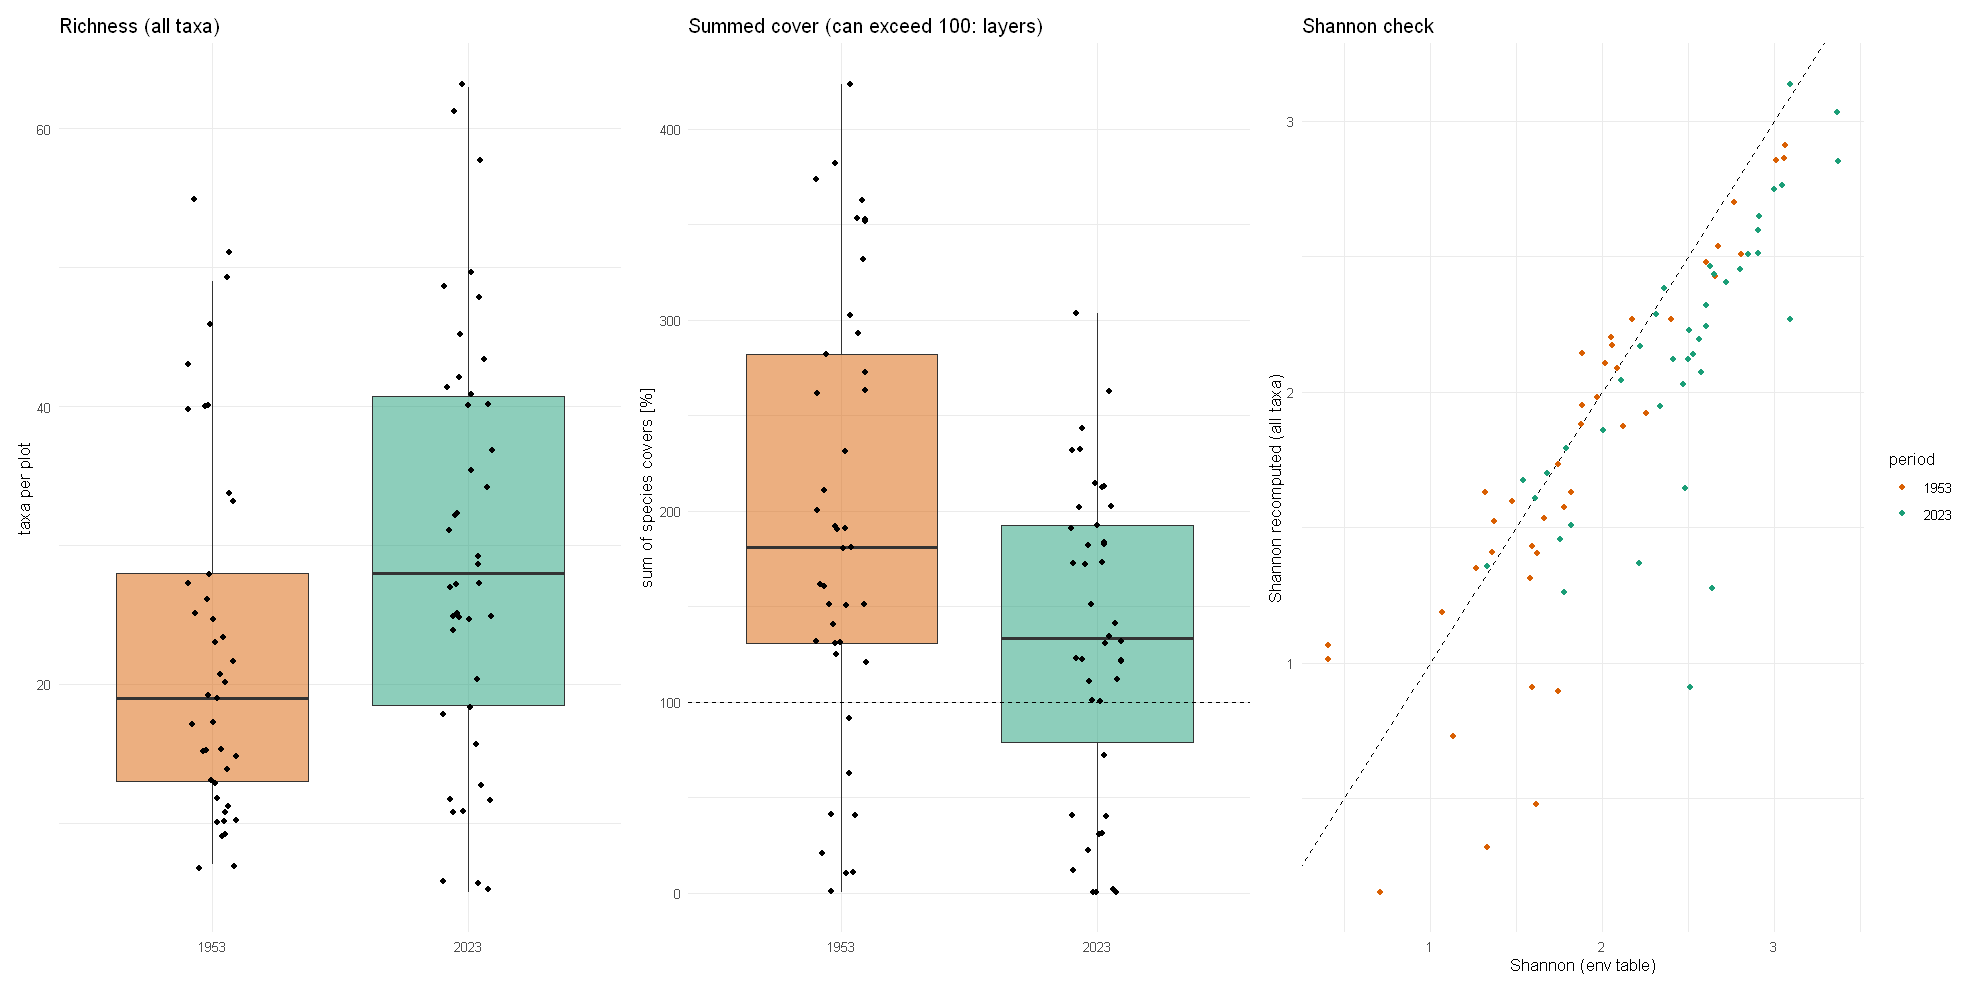

In [32]:
options(repr.plot.width = 18, repr.plot.height = 9)
rich <- rich %>%
  mutate(shannon_calc = diversity(comm[plot_id, ], "shannon"),
         shannon_vasc = diversity(comm[plot_id, vasc_taxa], "shannon"))

p1 <- ggplot(rich, aes(period, rich_all, fill = period)) + geom_boxplot(alpha = .5, outlier.shape = NA) +
  geom_jitter(width = .1) + scale_fill_manual(values = period_cols) + guides(fill = "none") +
  labs(y = "taxa per plot", x = NULL, title = "Richness (all taxa)")
p2 <- ggplot(rich, aes(period, cover_sum, fill = period)) + geom_boxplot(alpha = .5, outlier.shape = NA) +
  geom_jitter(width = .1) + scale_fill_manual(values = period_cols) + guides(fill = "none") +
  geom_hline(yintercept = 100, linetype = 2) +
  labs(y = "sum of species covers [%]", x = NULL, title = "Summed cover (can exceed 100: layers)")
p3 <- ggplot(rich, aes(shannon, shannon_calc, colour = period)) + geom_abline(linetype = 2) +
  geom_point(na.rm = TRUE) + scale_colour_manual(values = period_cols) +
  labs(x = "Shannon (env table)", y = "Shannon recomputed (all taxa)", title = "Shannon check")
p1 + p2 + p3

`geom_smooth()` using formula = 'y ~ x'


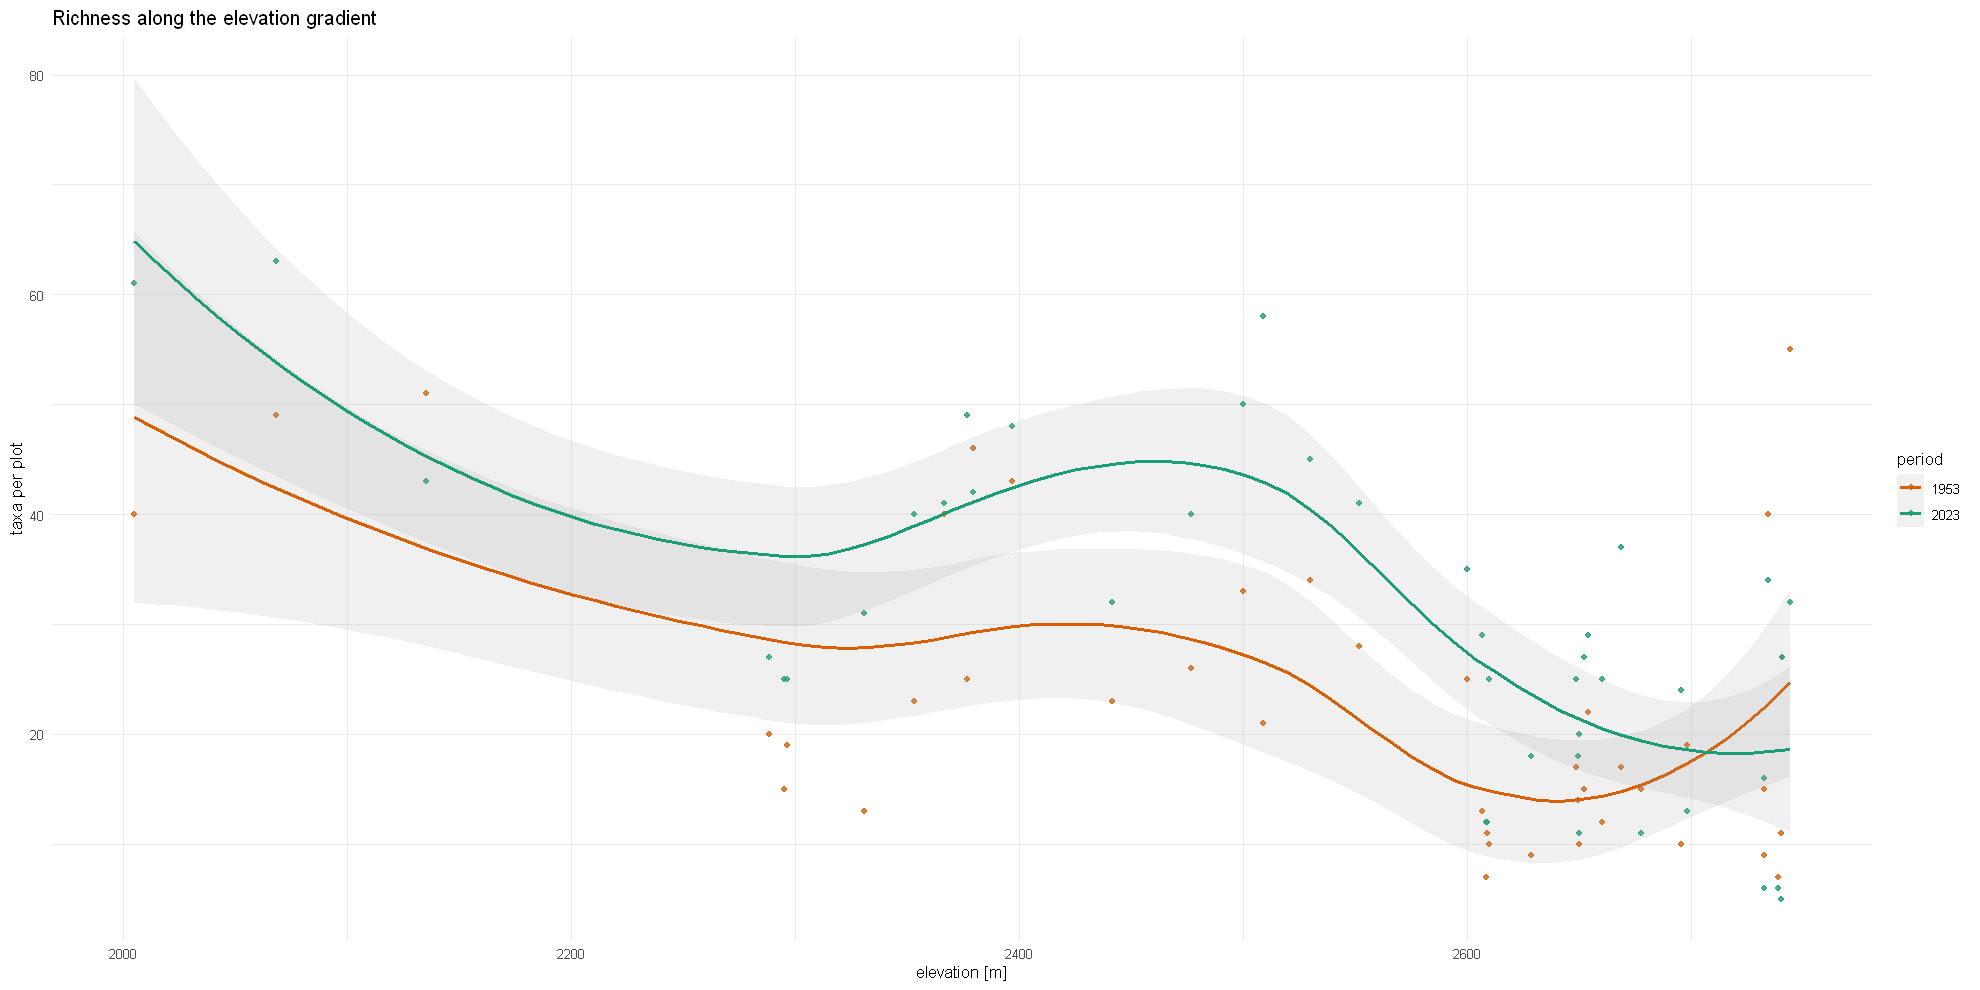

In [33]:
ggplot(rich, aes(elevation, rich_all, colour = period)) +
  geom_point(alpha = .8) + geom_smooth(method = "loess", se = TRUE, alpha = .15) +
  scale_colour_manual(values = period_cols) +
  labs(x = "elevation [m]", y = "taxa per plot", title = "Richness along the elevation gradient")

## 4.4 Species frequency, abundance and turnover

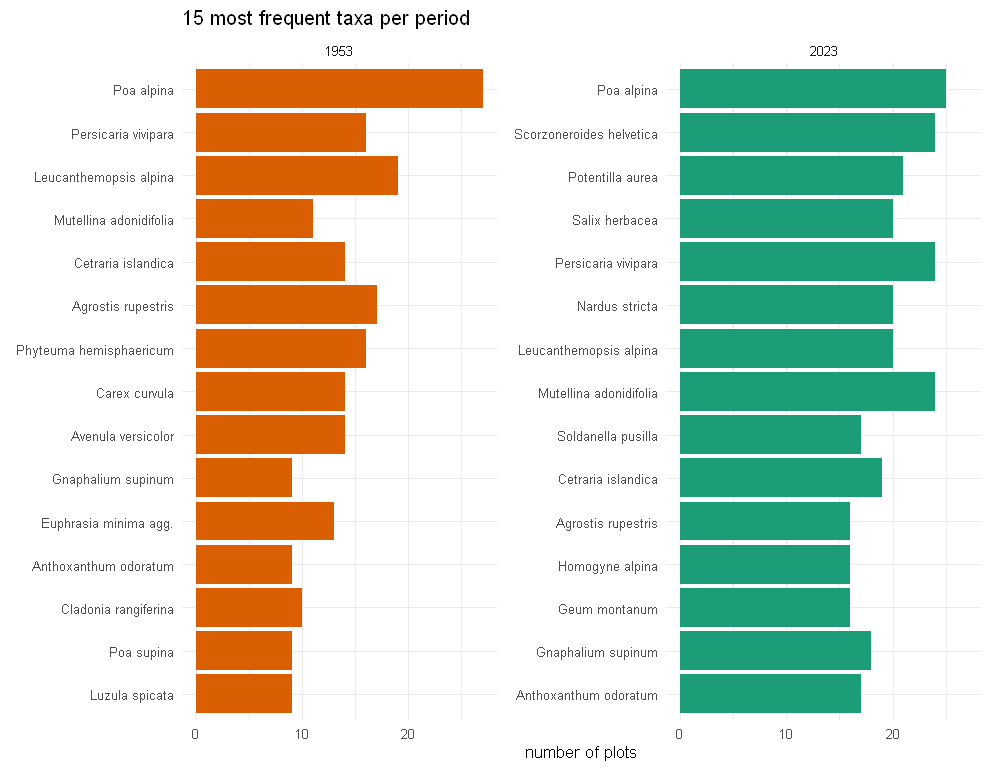

In [34]:
options(repr.plot.width = 9, repr.plot.height = 7)
long <- sp %>%
  pivot_longer(-plot_id, names_to = "taxon", values_to = "cover") %>%
  left_join(env %>% select(plot_id, base_id, period, elevation, assoc_abbr), by = "plot_id")

freq <- long %>% group_by(taxon, period) %>%
  summarise(n_occ = sum(cover > 0), mean_cover = mean(cover), .groups = "drop")

top_freq <- freq %>% group_by(period) %>% slice_max(n_occ, n = 15, with_ties = FALSE) %>% ungroup()
ggplot(top_freq, aes(n_occ, reorder(taxon, n_occ), fill = period)) +
  geom_col() + facet_wrap(~ period, scales = "free_y") +
  scale_fill_manual(values = period_cols) + guides(fill = "none") +
  labs(x = "number of plots", y = NULL, title = "15 most frequent taxa per period")

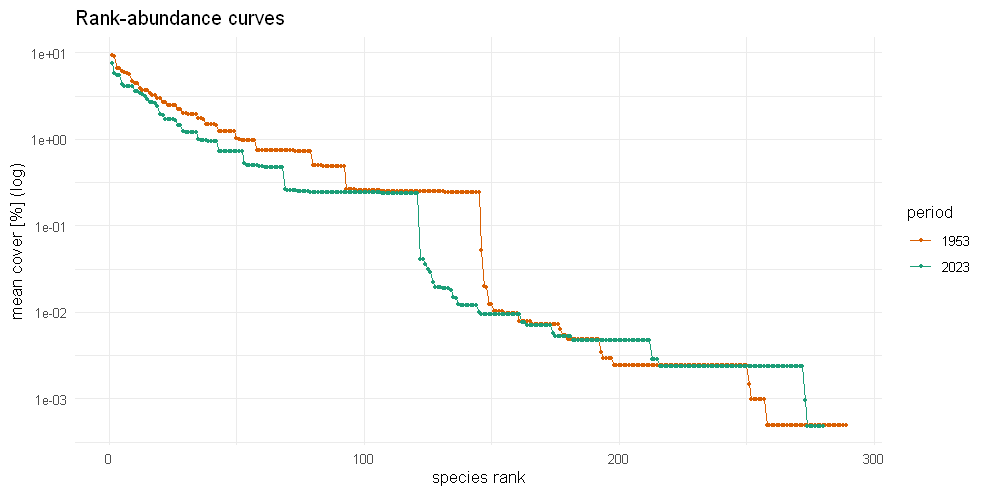

In [35]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
freq %>% filter(mean_cover > 0) %>% group_by(period) %>%
  arrange(desc(mean_cover), .by_group = TRUE) %>% mutate(rank = row_number()) %>%
  ggplot(aes(rank, mean_cover, colour = period)) + geom_line() + geom_point(size = 1) +
  scale_y_log10() + scale_colour_manual(values = period_cols) +
  labs(x = "species rank", y = "mean cover [%] (log)", title = "Rank-abundance curves")

In [36]:
options(repr.plot.width = 9, repr.plot.height = 5)
tax_status <- long %>% filter(cover > 0) %>% distinct(taxon, period) %>%
  mutate(v = 1) %>% pivot_wider(names_from = period, values_from = v, values_fill = 0) %>%
  rename(y1953 = `1953`, y2023 = `2023`) %>%
  mutate(status = case_when(y1953 == 1 & y2023 == 1 ~ "both",
                            y1953 == 1 ~ "only 1953", TRUE ~ "only 2023"))
tax_status %>% count(status) %>% kable(caption = "Taxa pool by period")

status,n
both,196
only 1953,93
only 2023,84


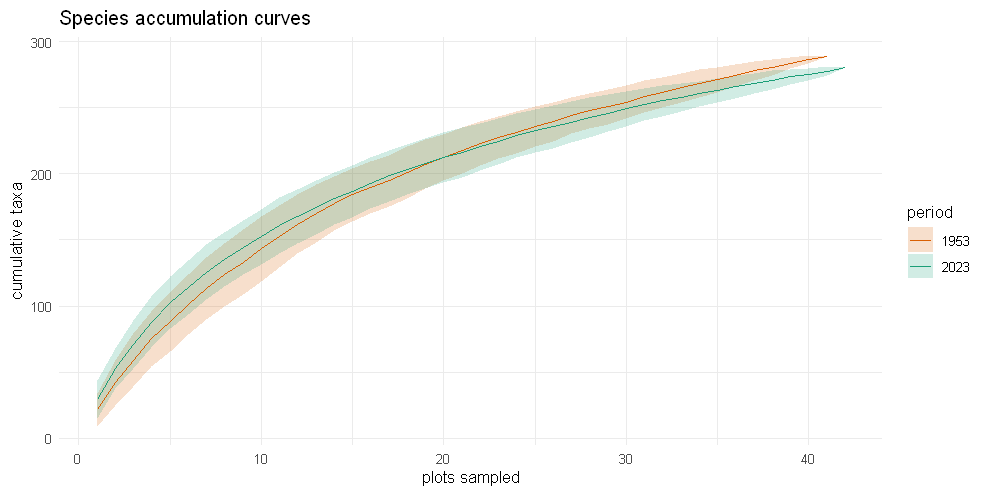

In [37]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
acc <- map_dfr(c("1953", "2023"), function(p) {
  ids <- env_sp$plot_id[env_sp$period == p]
  a <- specaccum(comm[ids, ], method = "random", permutations = 200)
  tibble(period = p, sites = a$sites, richness = a$richness, sd = a$sd)
})
ggplot(acc, aes(sites, richness, colour = period, fill = period)) +
  geom_ribbon(aes(ymin = richness - sd, ymax = richness + sd), alpha = .2, colour = NA) +
  geom_line() + scale_colour_manual(values = period_cols) + scale_fill_manual(values = period_cols) +
  labs(x = "plots sampled", y = "cumulative taxa", title = "Species accumulation curves")

# 5. Community change within plots (paired)

## 5.1 Gains, losses and turnover per plot

name,value
lost_mean,10.59
lost_median,9.00
gained_mean,17.88
gained_median,17.00
retained_mean,12.32
retained_median,10.00
bray_mean,0.73
bray_median,0.75
sorensen_mean,0.55
sorensen_median,0.54


`geom_smooth()` using formula = 'y ~ x'


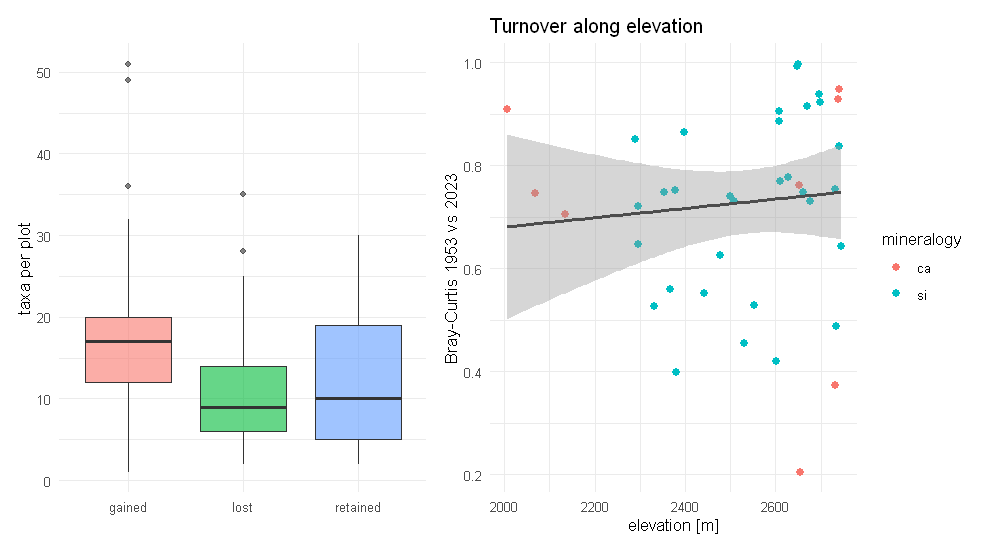

In [38]:
options(repr.plot.width = 9, repr.plot.height = 5)
A <- comm[pair_ids_sp, , drop = FALSE]                  # 1953
B <- comm[paste0(pair_ids_sp, "_23"), , drop = FALSE]   # 2023

bc  <- as.matrix(vegdist(comm, "bray"))
sor <- as.matrix(vegdist(comm, "bray", binary = TRUE))  # Sorensen

pair_turn <- tibble(
  base_id = pair_ids_sp,
  lost     = rowSums(A > 0 & !(B > 0)),
  gained   = rowSums(!(A > 0) & B > 0),
  retained = rowSums(A > 0 & B > 0),
  bray     = bc[cbind(pair_ids_sp, paste0(pair_ids_sp, "_23"))],
  sorensen = sor[cbind(pair_ids_sp, paste0(pair_ids_sp, "_23"))]
) %>%
  left_join(env %>% filter(period == "1953") %>% select(base_id, elevation, assoc_abbr, mineralogy), by = "base_id")

pair_turn %>% summarise(across(c(lost, gained, retained, bray, sorensen), list(mean = mean, median = median))) %>%
  pivot_longer(everything()) %>% kable(digits = 2)

p1 <- pair_turn %>% pivot_longer(c(lost, gained, retained)) %>%
  ggplot(aes(name, value, fill = name)) + geom_boxplot(alpha = .6) + guides(fill = "none") +
  labs(x = NULL, y = "taxa per plot")
p2 <- ggplot(pair_turn, aes(elevation, bray, colour = mineralogy)) + geom_point(size = 2) +
  geom_smooth(aes(group = 1), method = "lm", se = TRUE, colour = "grey30") +
  labs(x = "elevation [m]", y = "Bray-Curtis 1953 vs 2023", title = "Turnover along elevation")
p1 + p2

rho_bray_dMAT,rho_bray_dSnow,rho_bray_dLIVT
-0.13,0.23,-0.06


`geom_smooth()` using formula = 'y ~ x'


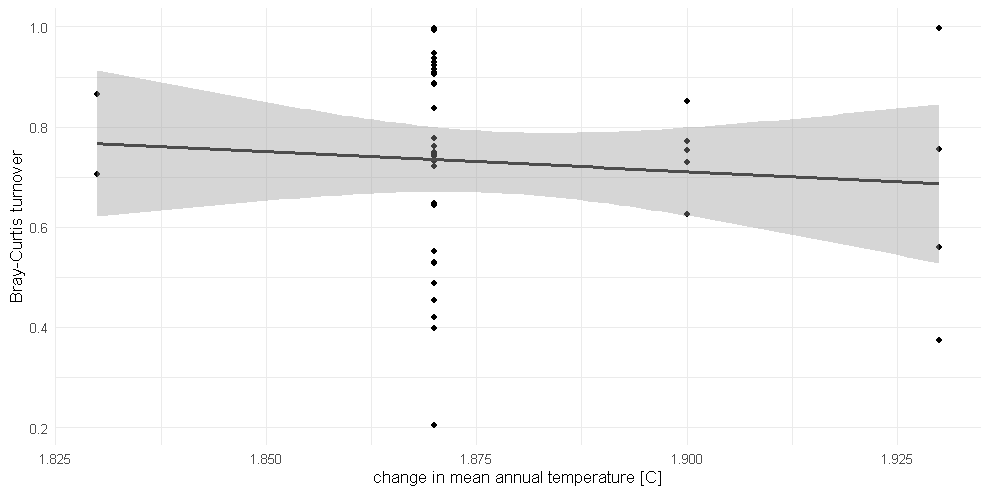

In [39]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
delta <- paired %>% mutate(delta = y2023 - y1953) %>%
  select(base_id, name, delta) %>% pivot_wider(names_from = name, values_from = delta, names_prefix = "d_")

pt <- pair_turn %>% left_join(delta, by = "base_id")

pt %>% summarise(
  rho_bray_dMAT  = cor(bray, d_mat, method = "spearman", use = "complete.obs"),
  rho_bray_dSnow = cor(bray, d_snow_days, method = "spearman", use = "complete.obs"),
  rho_bray_dLIVT = cor(bray, d_liv_temp, method = "spearman", use = "complete.obs")) %>% kable(digits = 2)

ggplot(pt, aes(d_mat, bray)) + geom_point() + geom_smooth(method = "lm", colour = "grey30") +
  labs(x = "change in mean annual temperature [C]", y = "Bray-Curtis turnover")

## 5.2 Ordination (NMDS) and PERMANOVA

NMDS stress: 0.145 


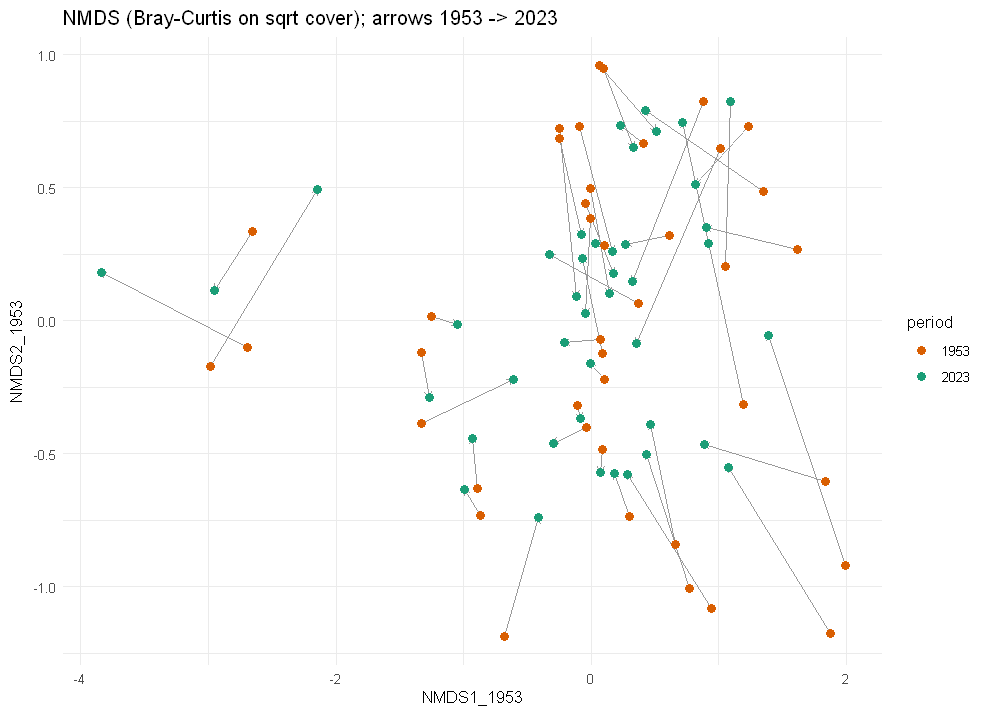

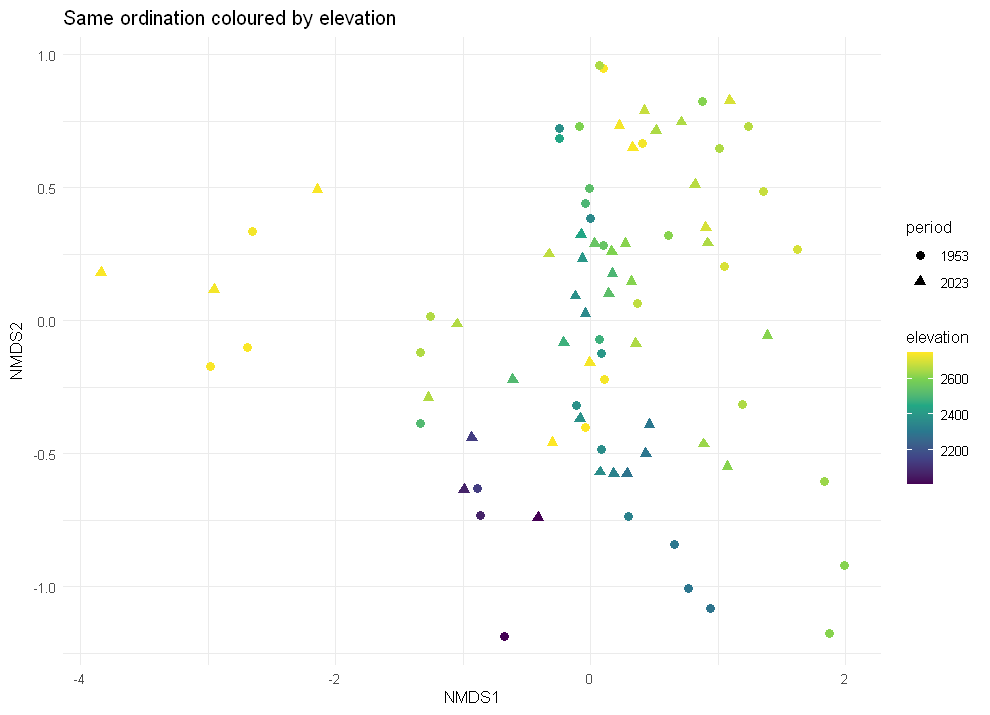

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6.5)
nmds <- metaMDS(sqrt(comm), distance = "bray", autotransform = FALSE, k = 2, trymax = 50, trace = FALSE)
cat("NMDS stress:", round(nmds$stress, 3), "\n")

nm <- as.data.frame(scores(nmds, display = "sites")) %>%
  rownames_to_column("plot_id") %>%
  left_join(env %>% select(plot_id, base_id, period, assoc_abbr, elevation), by = "plot_id")

nm_w <- nm %>% filter(base_id %in% pair_ids_sp) %>%
  select(base_id, period, NMDS1, NMDS2) %>%
  pivot_wider(names_from = period, values_from = c(NMDS1, NMDS2))

print(ggplot() +
  geom_segment(data = nm_w, aes(x = NMDS1_1953, y = NMDS2_1953, xend = NMDS1_2023, yend = NMDS2_2023),
               colour = "grey60", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(data = nm, aes(NMDS1, NMDS2, colour = period), size = 2.5) +
  scale_colour_manual(values = period_cols) +
  labs(title = "NMDS (Bray-Curtis on sqrt cover); arrows 1953 -> 2023"))

ggplot(nm, aes(NMDS1, NMDS2, colour = elevation, shape = period)) + geom_point(size = 2.5) +
  scale_colour_viridis_c() + labs(title = "Same ordination coloured by elevation")

In [41]:
options(repr.plot.width = 9, repr.plot.height = 5)
fit_vars <- c("elevation", "slope", "mat", "snow_days", "gdd5", "liv_temp", "liv_nutrients",
              "liv_moisture", "liv_ph", "liv_humus", "pc1_thermal", "pc2_soil", "cover_total")
ef <- envfit(nmds, as.data.frame(env_sp %>% select(all_of(fit_vars))), permutations = 999, na.rm = TRUE)
tibble(variable = names(ef$vectors$r), r2 = ef$vectors$r, p = ef$vectors$pvals) %>%
  arrange(desc(r2)) %>% mutate(across(where(is.numeric), ~ round(.x, 3))) %>%
  kable(caption = "Environmental vectors fitted to the NMDS")

variable,r2,p
liv_temp,0.646,0.001
liv_ph,0.639,0.001
liv_humus,0.506,0.001
pc2_soil,0.416,0.001
liv_moisture,0.343,0.001
liv_nutrients,0.283,0.001
elevation,0.270,0.001
pc1_thermal,0.264,0.001
cover_total,0.228,0.001
gdd5,0.200,0.001


In [42]:
d <- vegdist(sqrt(comm), "bray")
perm_paired <- how(nperm = 999, blocks = factor(env_sp$base_id))   # permute years within each plot
adonis2(d ~ period, data = env_sp, permutations = perm_paired)

bd <- betadisper(d, env_sp$period)
permutest(bd, permutations = 999)

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Model,1,0.7442088,0.02137303,1.769025,0.001
Residual,81,34.0757889,0.97862697,NA,NA
Total,82,34.8199977,1.00000000,NA,NA



Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq   Mean Sq      F N.Perm Pr(>F)   
Groups     1 0.03076 0.0307558 7.1506    999  0.007 **
Residuals 81 0.34840 0.0043012                        
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

# 6. Species-level change (paired plots)

## 6.1 Gains and losses per taxon

Exact McNemar test (binomial on discordant pairs) on presence/absence in the same plots.

In [43]:
sp_change <- tibble(
  taxon      = colnames(comm),
  occ_1953   = colSums(A > 0),
  occ_2023   = colSums(B > 0),
  lost       = colSums(A > 0 & !(B > 0)),
  gained     = colSums(!(A > 0) & B > 0),
  mean_cover_1953 = colMeans(A),
  mean_cover_2023 = colMeans(B)
) %>%
  mutate(d_occ = occ_2023 - occ_1953,
         d_cover = mean_cover_2023 - mean_cover_1953,
         p = map2_dbl(lost, gained, ~ if ((.x + .y) == 0) NA_real_ else binom.test(.x, .x + .y, 0.5)$p.value),
         p_adj = p.adjust(p, "BH")) %>%
  left_join(taxa_tbl %>% select(taxon, group, resolution), by = "taxon")

write_csv(sp_change, "outputs/species_change_paired.csv")

sp_change %>% filter(occ_1953 + occ_2023 >= 5) %>% arrange(p) %>% head(20) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

taxon,occ_1953,occ_2023,lost,gained,mean_cover_1953,mean_cover_2023,d_occ,d_cover,p,p_adj,group,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Scorzoneroides helvetica,9,23,0,14,2.934,1.749,14,-1.185,0.000,0.044,vascular,species
Potentilla aurea,8,21,0,13,3.663,3.198,13,-0.465,0.000,0.044,vascular,species
Coeloglossum viride,0,11,0,11,0.000,0.262,11,0.262,0.001,0.093,vascular,species
Nardus stricta,8,20,1,13,6.108,5.627,12,-0.481,0.002,0.093,vascular,species
Polytrichum sp.,1,13,1,13,0.000,1.966,12,1.966,0.002,0.093,non-vascular (moss/lichen),genus only (sp.)
Homogyne alpina,6,16,0,10,0.744,1.246,10,0.502,0.002,0.093,vascular,species
Sempervivum montanum,3,13,0,10,0.010,0.030,10,0.020,0.002,0.093,vascular,species
Mutellina adonidifolia,11,24,2,15,3.913,3.447,13,-0.466,0.002,0.093,vascular,species
Salix herbacea,6,19,2,15,3.664,4.171,13,0.507,0.002,0.093,vascular,species


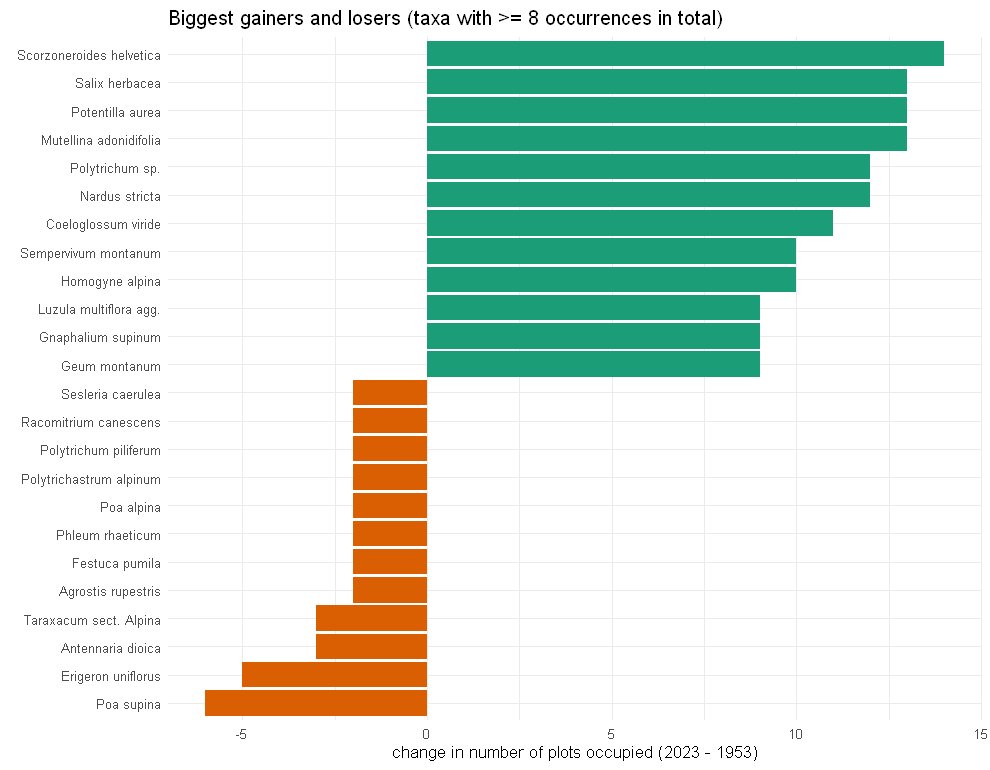

In [44]:
options(repr.plot.width = 9, repr.plot.height = 7)
wl <- sp_change %>% filter(occ_1953 + occ_2023 >= 8) %>%
  arrange(d_occ) %>% { bind_rows(head(., 12), tail(., 12)) }

ggplot(wl, aes(d_occ, reorder(taxon, d_occ), fill = d_occ > 0)) + geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"), guide = "none") +
  labs(x = "change in number of plots occupied (2023 - 1953)", y = NULL,
       title = "Biggest gainers and losers (taxa with >= 8 occurrences in total)")

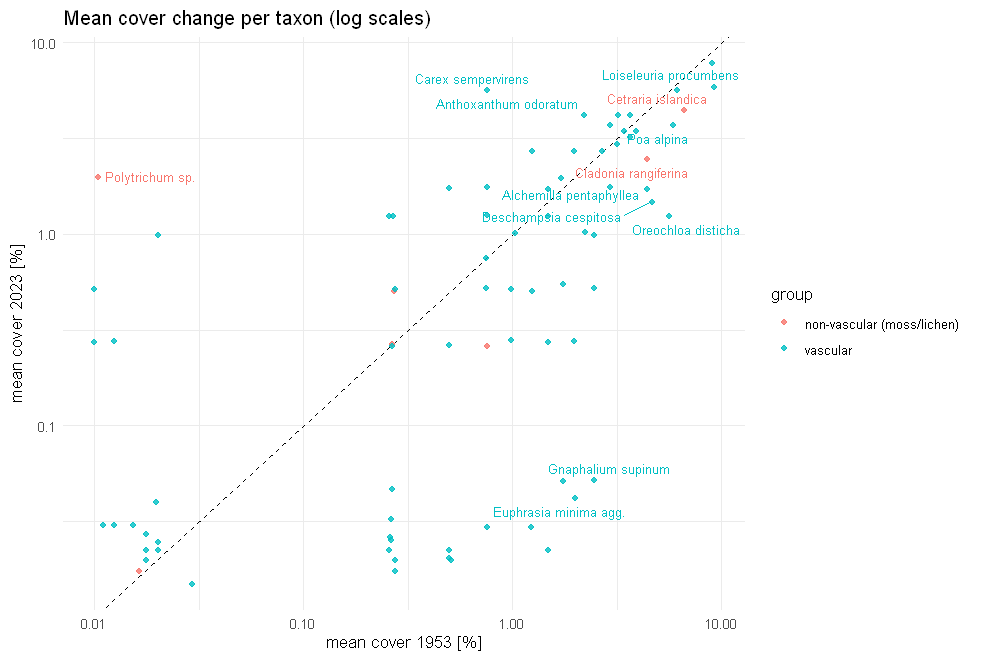

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)
sp_change %>% filter(occ_1953 + occ_2023 >= 8) %>%
  ggplot(aes(mean_cover_1953 + .01, mean_cover_2023 + .01, colour = group)) +
  geom_abline(linetype = 2) + geom_point(alpha = .8) +
  geom_text_repel(data = ~ slice_max(.x, abs(d_cover), n = 12, with_ties = FALSE),
                  aes(label = taxon), size = 3, show.legend = FALSE) +
  scale_x_log10() + scale_y_log10() +
  labs(x = "mean cover 1953 [%]", y = "mean cover 2023 [%]", title = "Mean cover change per taxon (log scales)")

## 6.2 Shift in elevational optimum

Cover-weighted mean elevation of the plots where each taxon occurs, per period
(an upward shift is the classic signature of warming).

Taxa with >= 5 plots in both periods: 48 
Median shift [m]: 28.3 

	Wilcoxon signed rank exact test

data:  optima$shift
V = 680, p-value = 0.3512
alternative hypothesis: true location is not equal to 0



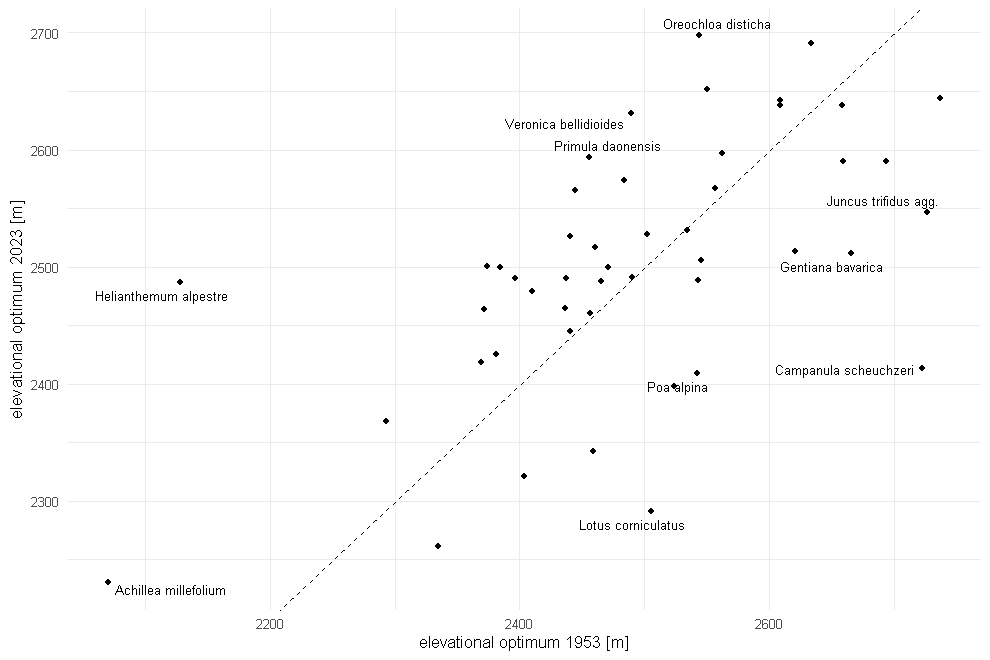

In [46]:
optima <- long %>% filter(cover > 0) %>%
  group_by(taxon, period) %>%
  summarise(n = n(), opt = weighted.mean(elevation, cover), .groups = "drop") %>%
  filter(n >= 5) %>%
  pivot_wider(names_from = period, values_from = c(n, opt)) %>%
  drop_na() %>% mutate(shift = opt_2023 - opt_1953)

cat("Taxa with >= 5 plots in both periods:", nrow(optima), "\n")
cat("Median shift [m]:", round(median(optima$shift), 1), "\n")
if (nrow(optima) > 5) print(wilcox.test(optima$shift, mu = 0))

ggplot(optima, aes(opt_1953, opt_2023)) + geom_abline(linetype = 2) + geom_point() +
  geom_text_repel(data = ~ slice_max(.x, abs(shift), n = 10, with_ties = FALSE), aes(label = taxon), size = 3) +
  labs(x = "elevational optimum 1953 [m]", y = "elevational optimum 2023 [m]")

# 7. First look at species-species associations

Spearman correlation of cover among the most frequent vascular taxa, within each period.
This is only descriptive: correlation of cover does not demonstrate interaction, and with
~41 plots per period it is noisy. It is meant to show where to dig deeper.

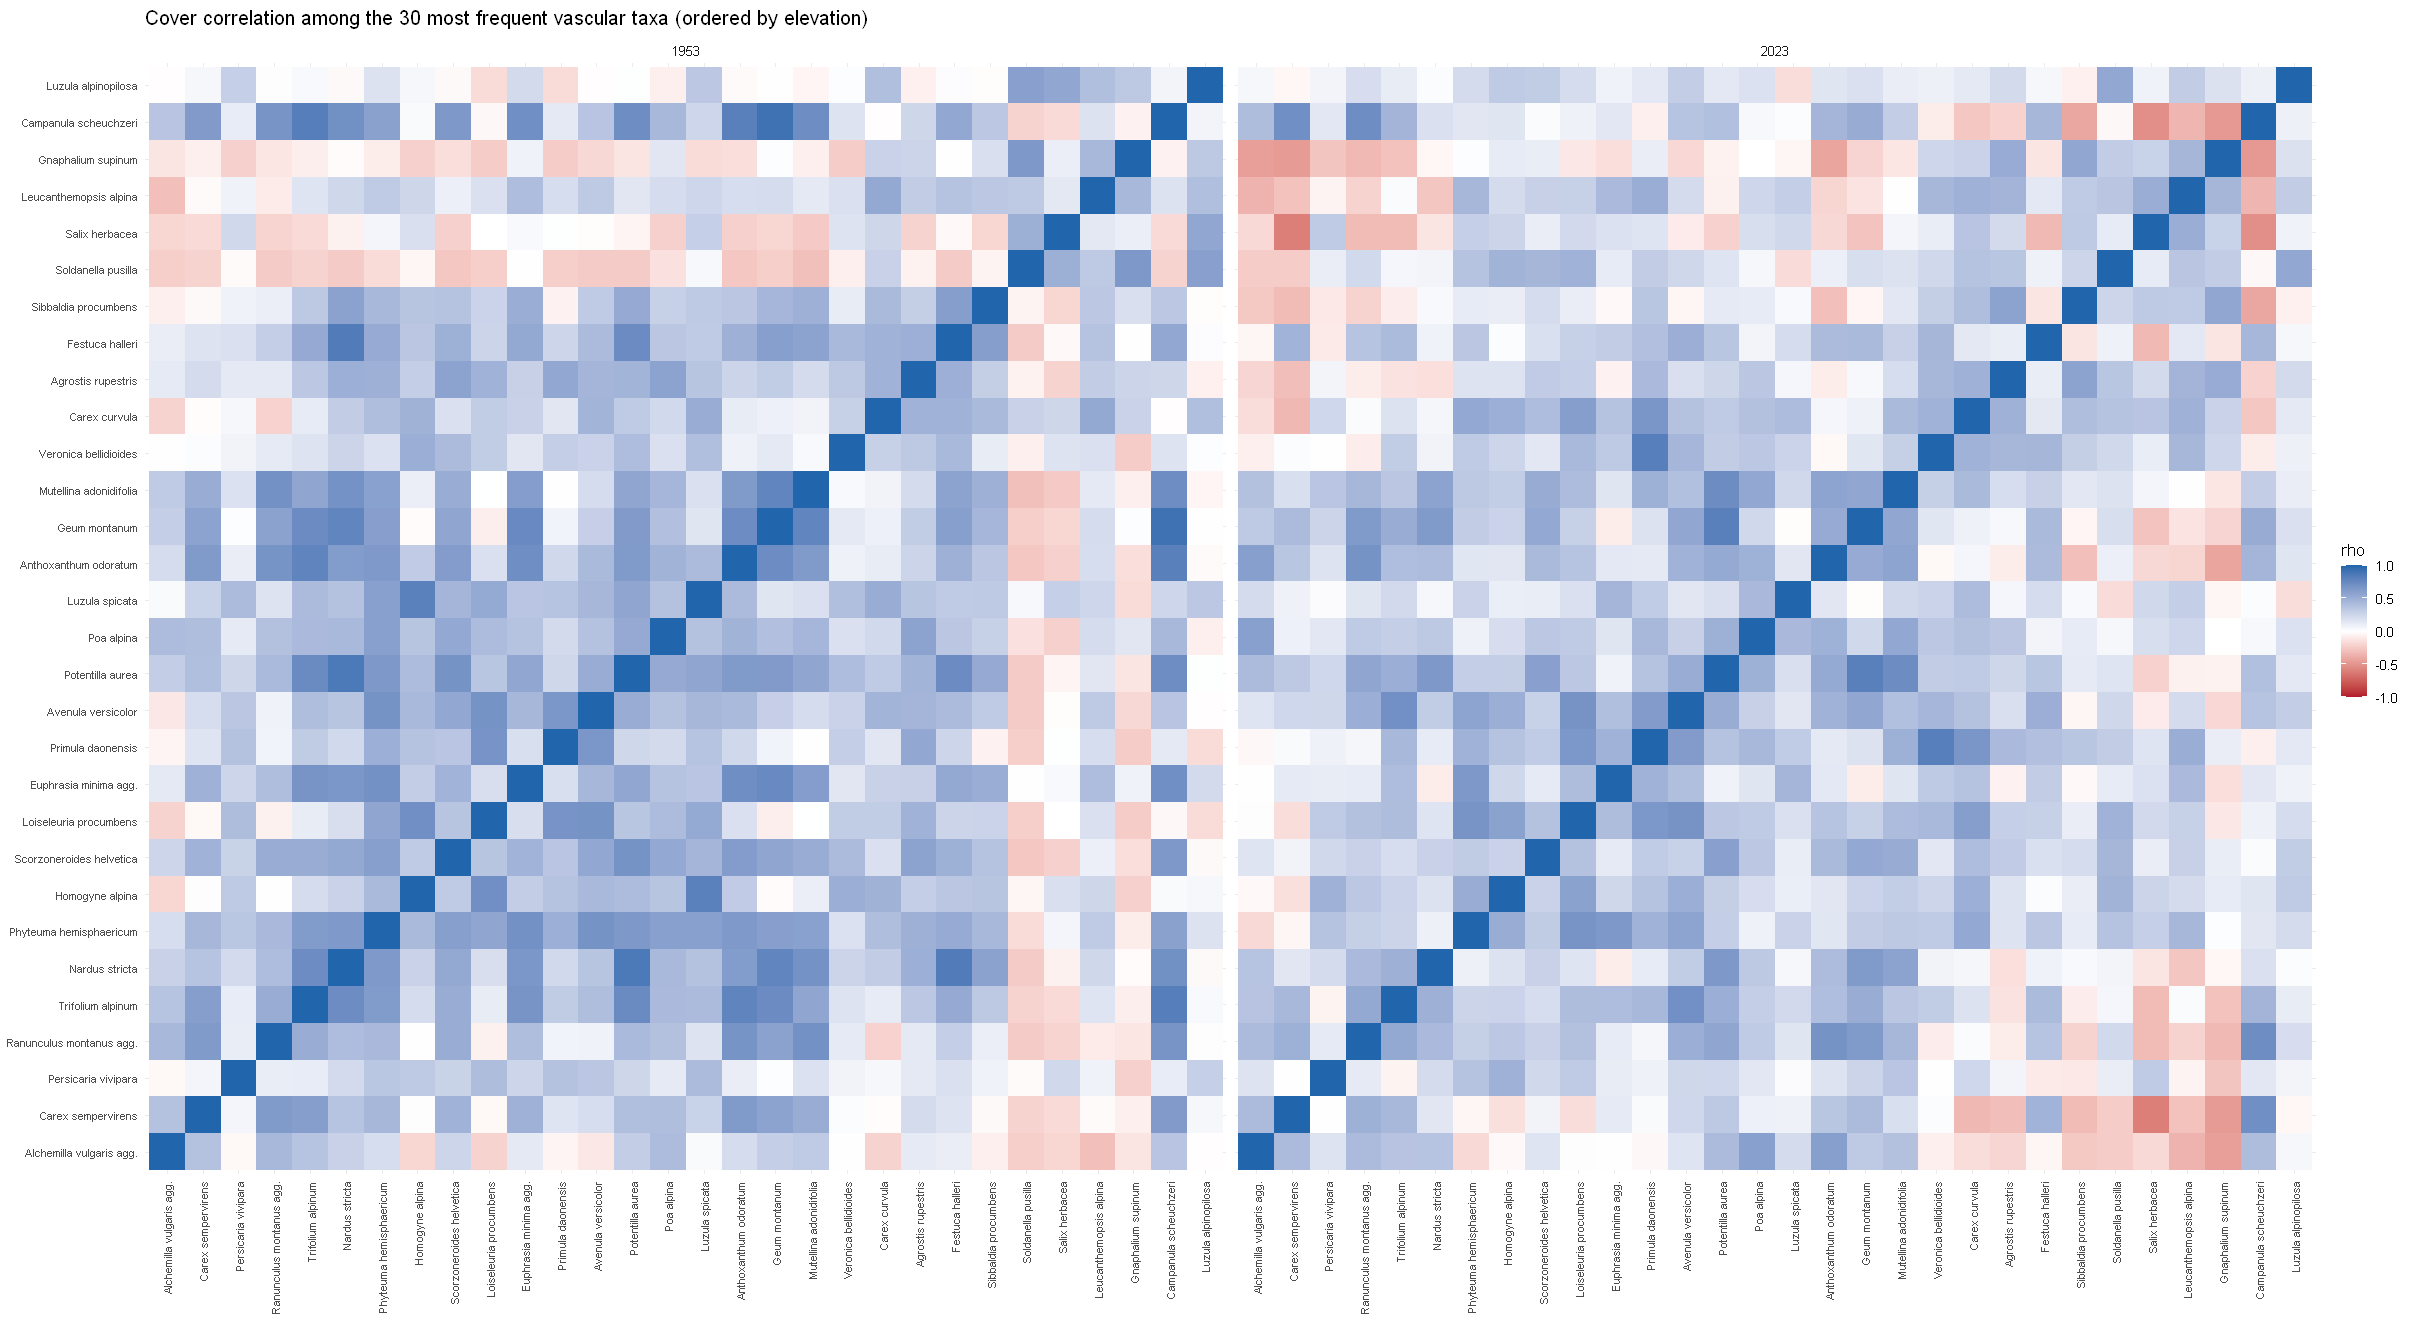

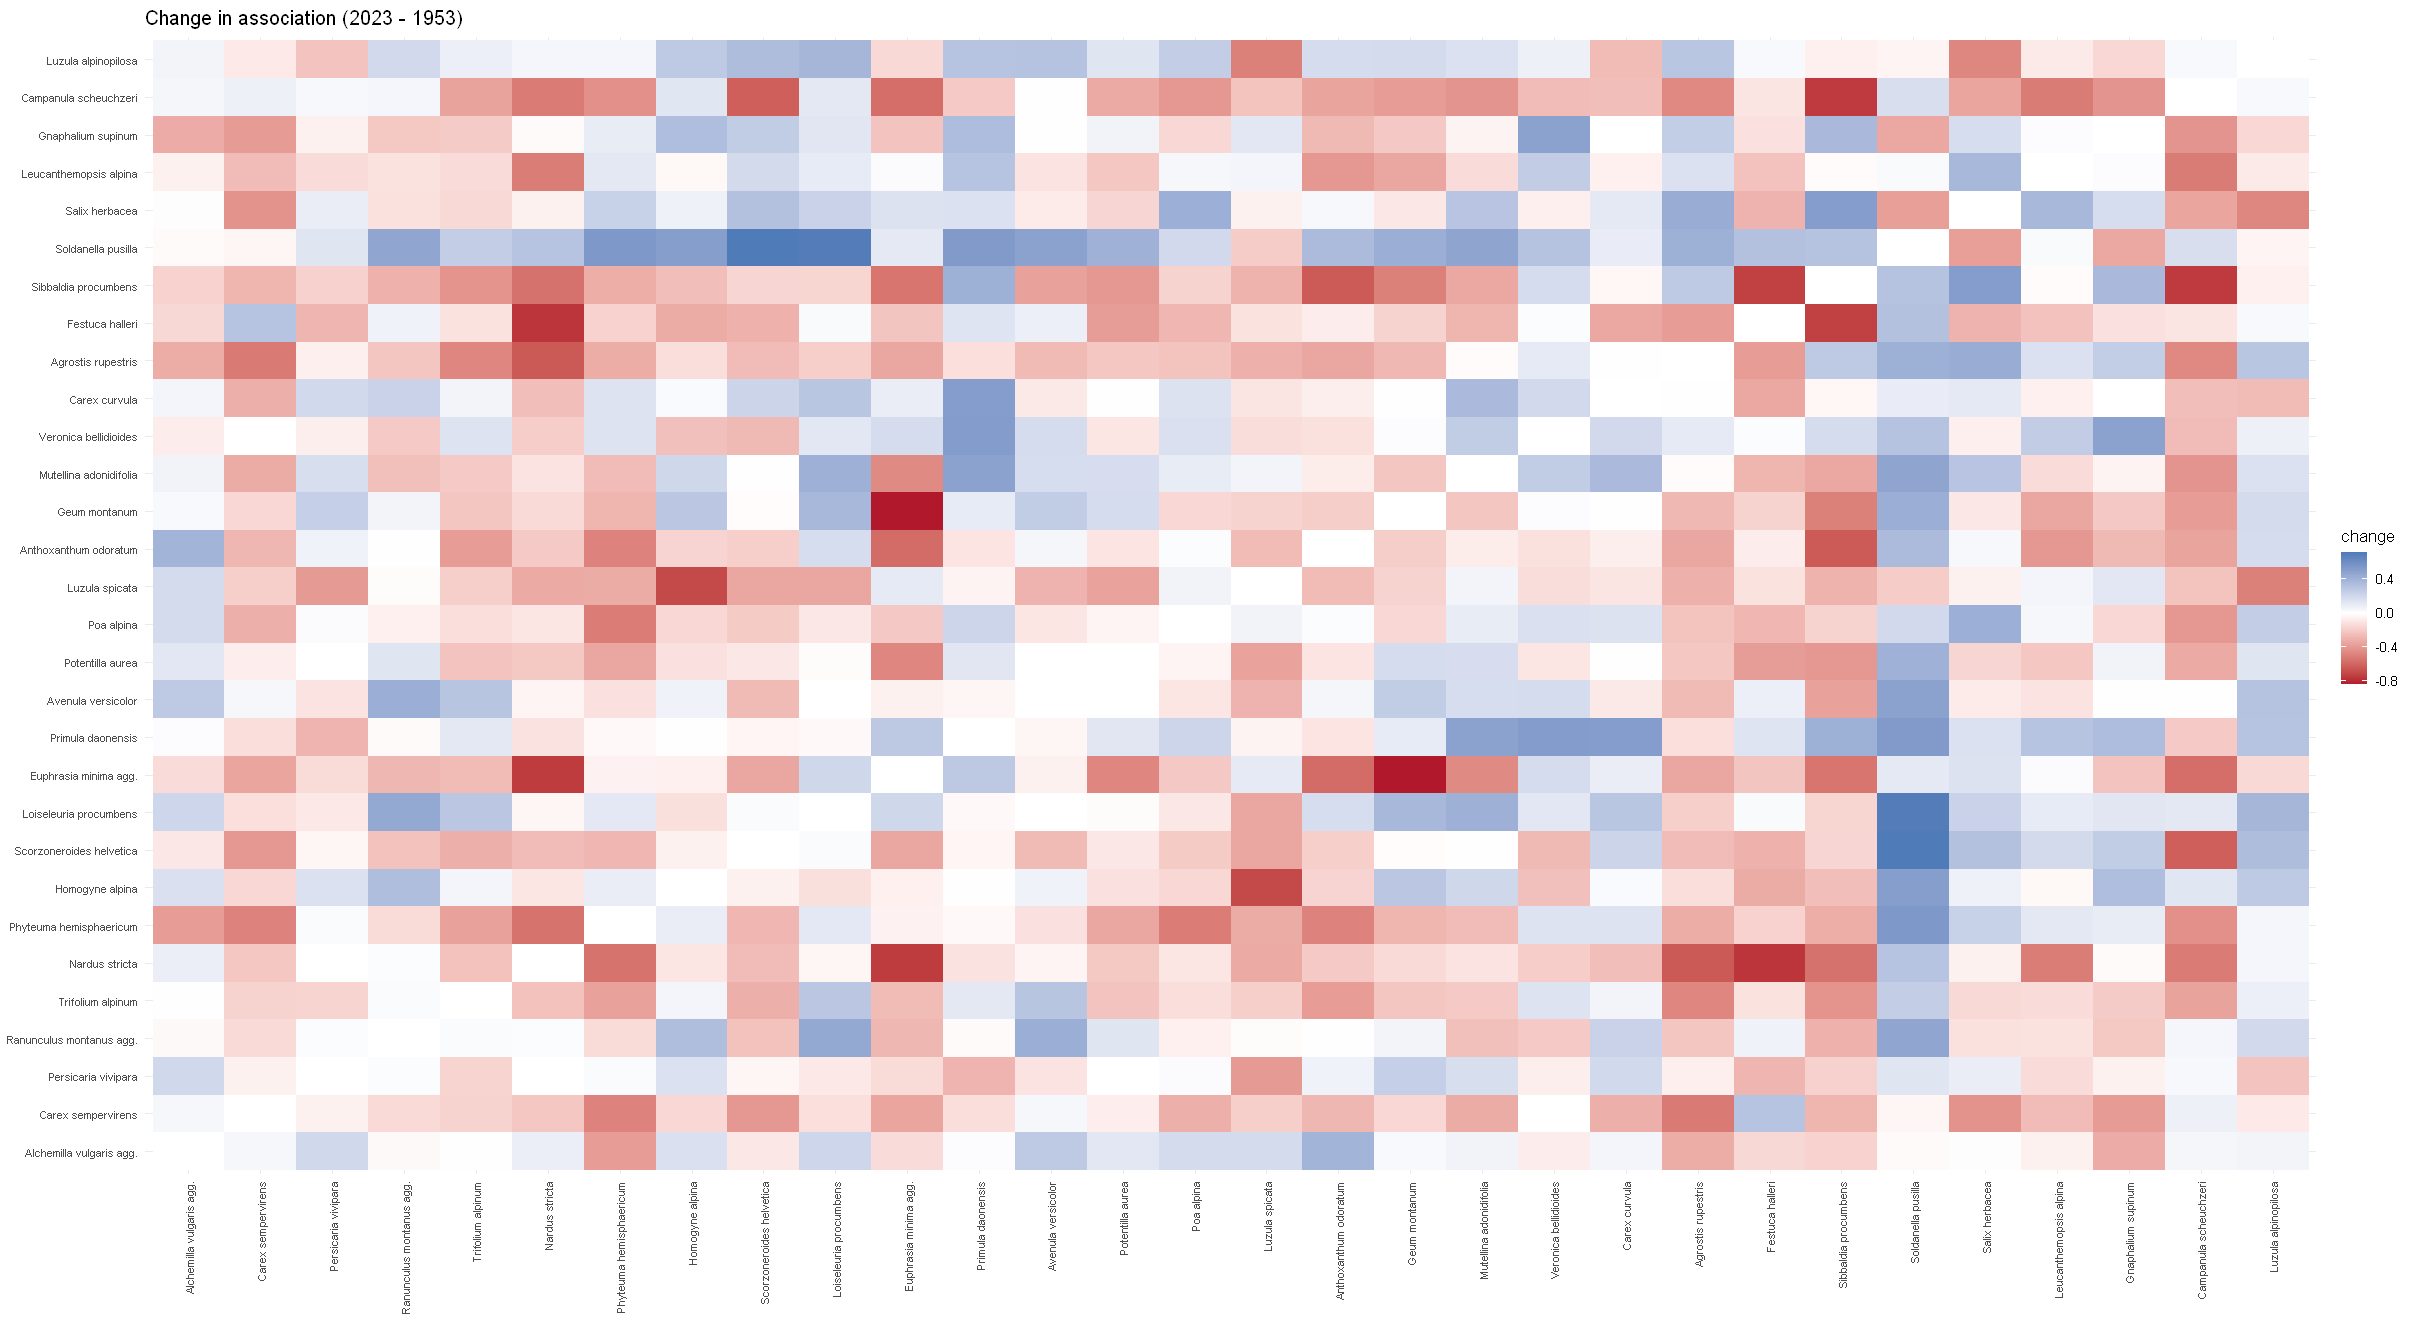

In [50]:
options(repr.plot.width = 22, repr.plot.height = 12)
top_taxa <- taxa_tbl %>% filter(group == "vascular") %>% slice_max(n_plots, n = 30, with_ties = FALSE) %>% pull(taxon)

# order taxa along the elevation gradient
elev_order <- long %>% filter(taxon %in% top_taxa, cover > 0) %>%
  group_by(taxon) %>% summarise(opt = weighted.mean(elevation, cover)) %>% arrange(opt) %>% pull(taxon)

cor_period <- function(p) {
  ids <- env_sp$plot_id[env_sp$period == p]
  m <- suppressWarnings(cor(comm[ids, top_taxa], method = "spearman"))
  as.data.frame(as.table(m)) %>% mutate(period = p)
}
cor_all <- map_dfr(c("1953", "2023"), cor_period) %>%
  mutate(Var1 = factor(Var1, levels = elev_order), Var2 = factor(Var2, levels = elev_order))

p1 <- ggplot(cor_all, aes(Var1, Var2, fill = Freq)) + geom_tile() + facet_wrap(~ period) +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", limits = c(-1, 1), na.value = "grey90") +
  labs(x = NULL, y = NULL, fill = "rho", title = "Cover correlation among the 30 most frequent vascular taxa (ordered by elevation)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5, size = 7), axis.text.y = element_text(size = 7))

cor_diff <- cor_all %>% pivot_wider(names_from = period, values_from = Freq) %>%
  mutate(diff = `2023` - `1953`)
p2 <- ggplot(cor_diff, aes(Var1, Var2, fill = diff)) + geom_tile() +
  scale_fill_gradient2(low = "#B2182B", mid = "white", high = "#2166AC", na.value = "grey90") +
  labs(x = NULL, y = NULL, fill = "change", title = "Change in association (2023 - 1953)") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = .5, size = 7), axis.text.y = element_text(size = 7))
print(p1)
print(p2)

# 8. Points to resolve before the main analysis

Fill this in as you read the outputs above. Things the data already suggest:

1. **Plot `17bis` (1953)** exists in the environmental table but not in the species table, so only 41 plots are paired for species analyses (42 for environmental ones).
2. **Non-standard cover values** (e.g. 0.12, 0.2, 2, 10.1, 30.1, 40, 44, 50.02): not part of the conversion scale in the README. Probably summed or merged taxa; decide how to treat them.
3. **Summed cover per plot can exceed 100 %** (layers), so relative abundance should be computed explicitly if needed.
4. **`total vegetation cover`** has a missing value; some plots show 5 % total cover while calculated cover is much lower or higher: check the estimate vs calculated plot in section 1.3.
5. **Livestock units** is constant (308) in 1953, so it is fully confounded with period.
6. **Labels:** association abbreviations are inconsistent (`Sha` vs `SHa`, `LC` vs `LC/CC`, `FV` missing from README) and habitat names contain typos ("Pionneer", "calcaerous").
7. **Relative cover columns are proportions (0-1)** although named `[%]`.
8. **Climate variables are modelled (ClimateEU)**, so the 1953 vs 2023 climate difference is a model product, not a plot measurement.
9. The README lists `LIV igt` but the file has `Landolt indicator value light`.

In [48]:
options(repr.plot.width = 9, repr.plot.height = 5)
sessionInfo()

R version 4.3.3 (2024-02-29 ucrt)
Platform: x86_64-w64-mingw32/x64 (64-bit)
Running under: Windows 11 x64 (build 26300)

Matrix products: default


locale:
[1] LC_COLLATE=French_Switzerland.utf8  LC_CTYPE=French_Switzerland.utf8   
[3] LC_MONETARY=French_Switzerland.utf8 LC_NUMERIC=C                       
[5] LC_TIME=French_Switzerland.utf8    

time zone: Europe/Zurich
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] knitr_1.50      ggrepel_0.9.6   patchwork_1.3.0 vegan_2.6-10   
 [5] lattice_0.22-5  permute_0.10-0  readxl_1.4.5    lubridate_1.9.4
 [9] forcats_1.0.1   stringr_1.6.0   dplyr_1.1.4     purrr_1.0.4    
[13] readr_2.1.5     tidyr_1.3.1     tibble_3.2.1    ggplot2_4.0.2  
[17] tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] generics_0.1.4     stringi_1.8.7      hms_1.1.4          digest_0.6.37     
 [5] magrittr_2.0.3     evaluate_1.0.5     grid_4.3.3  